In [ ]:
import subprocess, sys, os
subprocess.check_call([sys.executable,'-m','pip','install','-q',
    'transformers==5.17.0','accelerate==1.14.0','scikit-learn==1.6.1','gdown','pyarrow'])
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
import torch, transformers, accelerate, sklearn, numpy as np, pandas as pd
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.manual_seed(42); np.random.seed(42)
print('torch', torch.__version__, '| transformers', transformers.__version__,
      '| accelerate', accelerate.__version__, '| sklearn', sklearn.__version__, '| numpy', np.__version__)
print('GPU', torch.cuda.get_device_name(0), round(torch.cuda.get_device_properties(0).total_memory/2**30,1), 'GiB')
assert transformers.__version__ == '5.17.0'

torch 2.11.0+cu128 | transformers 5.17.0 | accelerate 1.14.0 | sklearn 1.6.1 | numpy 2.1.3
GPU NVIDIA A100-SXM4-40GB 39.5 GiB


In [ ]:
from google.colab import drive; drive.mount('/content/drive')
import json, re, string, unicodedata, ast, hashlib, gdown
from pathlib import Path

ROOT = Path('/content/drive/MyDrive/Grad_share/data_share/E15'); ROOT.mkdir(parents=True, exist_ok=True)
WORK = Path('/content/e15_in'); WORK.mkdir(exist_ok=True)
SRC = {'behavior': ('1RXvW6o552ZNZn1PUMRaf8CEDMIUpqQOr', 'p8s_behavior_v2.csv'),
       'klabels':  ('1LMrQ3R4XWTcBbDn3kk2mR1iTITYw-KFF', 'k_relabel_v2.parquet')}
PATHS = {}
for k, (fid, fn) in SRC.items():
    p = WORK/fn
    if not p.exists(): gdown.download(id=fid, output=str(p), quiet=True)
    PATHS[k] = p
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()

F = pd.read_csv(PATHS['behavior']).reset_index(drop=True)
lab = pd.read_parquet(PATHS['klabels'])
km = lab.drop_duplicates('question').set_index('question')['kside_corr'].map({'K+':1,'K-':0,'K−':0})
F['k'] = F.question.map(km); F['c'] = F.ctx_label.map({'C+':1,'C-':0,'C−':0})
assert F[['k','c']].notna().all().all(); F[['k','c']] = F[['k','c']].astype(int)
F['state'] = np.where(F.k==1, np.where(F.c==1,0,1), np.where(F.c==1,3,2))   # 0 K+C+,1 K+C-,2 K-C-,3 K-C+
F['row'] = np.arange(len(F))
g = F.groupby('question').c
assert len(F)==1224 and F.question.nunique()==612 and g.size().eq(2).all() and g.sum().eq(1).all()

def gold_aliases(v):
    try: items = json.loads(str(v))
    except Exception:
        try: items = ast.literal_eval(str(v))
        except Exception: items = [str(v)]
    return [str(x) for x in ([items] if isinstance(items,str) else items)]
F['aliases'] = F.gold.map(gold_aliases)
PROP_COL = 'prop' if 'prop' in F.columns else None
print('columns:', list(F.columns)); print('PROP_COL =', PROP_COL)

# outer fold: E11/E14와 동일 규칙(질문 단위, K 층화, seed 42) → 비교 가능성 유지
q = F[['question','k']].drop_duplicates().sort_values('question').reset_index(drop=True)
rng = np.random.default_rng(42); fmap = {}
for cls in (0,1):
    ids = q.loc[q.k.eq(cls),'question'].to_numpy().copy(); rng.shuffle(ids)
    fmap.update({s: i%5 for i,s in enumerate(ids)})
F['fold'] = F.question.map(fmap)
# inner fold: outer train 질문만 4분할 (test 행은 -1)
for o in range(5):
    col = f'inner{o}'; F[col] = -1
    tq = q[q.question.map(fmap).ne(o)]
    r2 = np.random.default_rng(42 + 100*o); imap = {}
    for cls in (0,1):
        ids = tq.loc[tq.k.eq(cls),'question'].to_numpy().copy(); r2.shuffle(ids)
        imap.update({s: i%4 for i,s in enumerate(ids)})
    m = F.fold.ne(o); F.loc[m, col] = F.loc[m,'question'].map(imap).astype(int)
assert F.groupby('question').fold.nunique().eq(1).all()          # pair 누수 없음
print(pd.crosstab(F.fold, F.state))

# 채점기: 주=fixed(약어·이니셜 보호), 보조=old(팀 기존)
ABBR = {'dr','mr','mrs','ms','st','jr','sr','mt','ft','no','vs','prof','gen','sgt','capt','lt','col'}
def norm_answer(s):
    s = unicodedata.normalize('NFKC', str(s)).lower()
    s = ''.join(ch for ch in s if ch not in set(string.punctuation))
    return ' '.join(x for x in s.split() if x not in {'a','an','the'})
def _pre(raw):
    s = str(raw).strip().split('\n')[0].strip()
    return re.sub(r'^(answer|the answer is)\s*:?\s*', '', s, flags=re.I)
def _post(s): return re.sub(r'[.,;:\s]+$', '', s.strip().strip('"\'')).strip()
def trunc_old(raw): return _post(_pre(raw).split('. ')[0])
def trunc_fixed(raw):
    s = _pre(raw)
    for mt in re.finditer(r'\.\s+', s):
        toks = s[:mt.start()].split(); prev = toks[-1] if toks else ''
        if re.fullmatch(r'(?:[A-Z]\.)*[A-Z]', prev) or prev.lower() in ABBR: continue
        return _post(s[:mt.start()])
    return _post(s)
for x, y in [('Dr. Dre','Dr. Dre'), ('T.S. Eliot','T.S. Eliot'), ('Ronald D. Moore','Ronald D. Moore'),
             ('Paris. It is the capital','Paris'), ('Answer: Rome.','Rome'), ('"Milton Friedman"','Milton Friedman')]:
    assert trunc_fixed(x)==y, (x, trunc_fixed(x))
def score(raw, i, fixed=True):
    r = F.iloc[i]; p = norm_answer((trunc_fixed if fixed else trunc_old)(raw))
    ca = norm_answer(r.answer_surface)
    return int(any(p==norm_answer(g) for g in r.aliases)), int(bool(ca) and ca in p)

F[['row','question','fold']+[f'inner{o}' for o in range(5)]].to_parquet(ROOT/'folds.parquet', index=False)
print('scorer tests OK | folds saved')

Mounted at /content/drive
columns: ['question', 'gold', 'prop', 'kside', 'knows', 'A_cb', 'ctx_id', 'ctx_title', 's_wiki_title', 'orig_gold', 'ctx_label', 'ctx_text', 'answer_surface', 'ans_start', 'ans_end', 'wrong_answer', 'answer', 'behavior', 'final_correct', 'gold_list', 'kside_k', 'kside_new', 'kside_corr', 'k_agree', 'cell_k', 'k', 'c', 'state', 'row', 'aliases']
PROP_COL = prop
state   0   1   2   3
fold                 
0      73  73  50  50
1      73  73  50  50
2      72  72  50  50
3      72  72  50  50
4      72  72  50  50
scorer tests OK | folds saved


In [ ]:
from getpass import getpass
from huggingface_hub import login, model_info
from transformers import AutoTokenizer, AutoModelForCausalLM
import requests
login(token=getpass('HF token: ').strip(), add_to_git_credential=False)
MODEL_ID = 'meta-llama/Llama-3.1-8B-Instruct'
REV = model_info(MODEL_ID).sha
assert REV.startswith('0e9e39f'), f'revision 변경됨: {REV}'

SYSTEM_PROMPT = ('You are a question answering system. '
 'Answer the question based on the given context. '
 'Output the answer string itself and nothing else: no sentence, no explanation, '
 'no punctuation, no quotes. Keep it as short as possible (a name or a term).')
# 팀 원본(p8s-v2 고정 커밋)과 대조
URL = 'https://raw.githubusercontent.com/Ontology0/Graduation-Project/733d4e1f398c1eb9649cd9073925c2466111f16d/prompt/p8s_prompt.py'
try:
    src = requests.get(URL, timeout=30).text
    print('team prompt match:', SYSTEM_PROMPT.split('. ')[1] in src and 'no punctuation, no quotes' in src)
except Exception as e:
    print('prompt fetch 실패(수동 확인 필요):', e)

TOK = AutoTokenizer.from_pretrained(MODEL_ID, revision=REV)
TOK.padding_side = 'left'
if TOK.pad_token_id is None: TOK.pad_token = TOK.eos_token
MODEL = AutoModelForCausalLM.from_pretrained(MODEL_ID, revision=REV, dtype=torch.bfloat16,
          device_map={'':'cuda:0'}, attn_implementation='sdpa').eval()
for p_ in MODEL.parameters(): p_.requires_grad_(False)
NL, NH, HD = MODEL.config.num_hidden_layers, MODEL.config.num_attention_heads, MODEL.config.hidden_size//MODEL.config.num_attention_heads
DECODE_KW = dict(skip_special_tokens=True, clean_up_tokenization_spaces=False)

def render(i):
    r = F.iloc[i]
    user = 'Context: ' + str(r.ctx_text) + '\nQuestion: ' + str(r.question) + '\nAnswer:'
    text = TOK.apply_chat_template([{'role':'system','content':SYSTEM_PROMPT},{'role':'user','content':user}],
                                   tokenize=False, add_generation_prompt=True)
    enc = TOK(text, add_special_tokens=False, return_offsets_mapping=True)
    base = text.rfind(user); assert base > 0
    neg = max(j for j,(s,e) in enumerate(enc['offset_mapping']) if e <= base)   # context 이전 마지막 토큰(음성대조)
    return enc['input_ids'], neg

ENC = [render(i) for i in range(len(F))]
LENS = np.array([len(x[0]) for x in ENC])
assert len({tuple(ENC[i][0][:ENC[i][1]+1]) for i in range(len(F))}) == 1   # 음성대조 위치까지 prefix 전 행 동일
ORDER = np.argsort(LENS, kind='stable')
BATCHES = [ORDER[s:s+16].tolist() for s in range(0, len(ORDER), 16)]      # 전 조건 공통 배치 (고정)
json.dump(BATCHES, open(ROOT/'batches_bs16.json','w'))

MANIFEST = {'model_rev': REV, 'transformers': transformers.__version__, 'torch': torch.__version__,
            'sha_behavior': sha(PATHS['behavior']), 'sha_klabels': sha(PATHS['klabels']),
            'sha_folds': sha(ROOT/'folds.parquet'), 'sha_batches': sha(ROOT/'batches_bs16.json'),
            'prompt': 'p8s-v2 (Context→Question), system=SYSTEM_PROMPT', 'scorer_primary': 'trunc_fixed',
            'K_label': 'kside_corr (report only)', 'rho_hi': 0.12, 'rho_A0': 0.06, 'layers_write': [14,15,16,17,18],
            'gate_read': 'layers[13] o_proj-input last token'}
json.dump(MANIFEST, open(ROOT/'manifest.json','w'), indent=2)
print('rev', REV[:12], '| prompt len min/med/max', LENS.min(), int(np.median(LENS)), LENS.max(), '| batches', len(BATCHES))
print(TOK.decode(ENC[0][0])[-300:])

HF token: ··········
team prompt match: True


config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/55.4k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

...

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/184 [00:00<?, ?B/s]

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


rev 0e9e39f249a1 | prompt len min/med/max 206 238 377 | batches 77
vie ""Kondaveeti Simham"" (1981), starring N. T. Rama Rao, Sridevi in the lead roles and both the movies are made under the same banner and director. ""Kondaveeti Simham"" itself was a remake of the 1974
Question: What genre is Kanoon?
Answer:<|eot_id|><|start_header_id|>assistant<|end_header_id|>




In [ ]:
import time
WRITE_LAYERS = [14,15,16,17,18]
EOS = {TOK.eos_token_id, TOK.convert_tokens_to_ids('<|eot_id|>')} - {None}
EOS_T = torch.tensor(sorted(EOS), device='cuda')

def pack(rows):
    T = max(LENS[i] for i in rows); B = len(rows)
    ids = torch.full((B,T), TOK.pad_token_id, dtype=torch.long); mask = torch.zeros((B,T), dtype=torch.long)
    for j,i in enumerate(rows):
        n = LENS[i]; ids[j,T-n:] = torch.tensor(ENC[i][0]); mask[j,T-n:] = 1
    ids, mask = ids.cuda(), mask.cuda()
    return ids, mask, (mask.cumsum(-1)-1).clamp_min(0)

class Steer:
    """P9: L14–18 non-pad 전 토큰(prefill+decode)에 row별 Δ 가산. delta: (B, len(WRITE_LAYERS), 4096) 또는 None"""
    def __init__(self, delta): self.delta, self.tokmask, self.h = delta, None, []
    def __enter__(self):
        if self.delta is None: return self
        for li, L in enumerate(WRITE_LAYERS):
            def hook(mod, args, out, li=li):
                h = out[0] if isinstance(out, tuple) else out
                add = self.delta[:, li, :].to(h.dtype)[:, None, :] * self.tokmask[:, -h.shape[1]:, None].to(h.dtype)
                h = h + add
                return (h,) + tuple(out[1:]) if isinstance(out, tuple) else h
            self.h.append(MODEL.model.layers[L].register_forward_hook(hook))
        return self
    def __exit__(self, *a):
        for x in self.h: x.remove()

@torch.inference_mode()
def generate(tag, delta_fn=None, max_new=192):
    """delta_fn(rows)->np/torch (B,5,4096) 또는 None. 결과를 ROOT/gen_{tag}.parquet에 저장, 있으면 재사용."""
    out_p = ROOT/f'gen_{tag}.parquet'
    if out_p.exists(): print('skip', tag); return pd.read_parquet(out_p)
    recs, t0 = [], time.time()
    for rows in BATCHES:
        ids, mask, pos = pack(rows)
        d = None if delta_fn is None else torch.as_tensor(delta_fn(rows), device='cuda', dtype=torch.float32)
        st = Steer(d)
        with st:
            st.tokmask = mask
            o = MODEL.model(input_ids=ids, attention_mask=mask, position_ids=pos, use_cache=True)
            past, logits = o.past_key_values, MODEL.lm_head(o.last_hidden_state[:, -1, :])
            B = len(rows); ended = torch.zeros(B, dtype=torch.bool, device='cuda'); toks = []
            for _ in range(max_new):
                nxt = logits.argmax(-1); nxt = torch.where(ended, torch.full_like(nxt, TOK.pad_token_id), nxt)
                toks.append(nxt); ended |= torch.isin(nxt, EOS_T)
                if ended.all(): break
                mask = torch.cat([mask, (~ended).long()[:, None] | 1], -1); st.tokmask = mask
                pos = (mask.sum(-1) - 1)[:, None]
                o = MODEL.model(input_ids=nxt[:, None], attention_mask=mask, position_ids=pos,
                                past_key_values=past, use_cache=True)
                past, logits = o.past_key_values, MODEL.lm_head(o.last_hidden_state[:, -1, :])
        gen = torch.stack(toks, 1).cpu()
        for j, i in enumerate(rows):
            g = gen[j].tolist(); cut = next((t for t, x in enumerate(g) if x in EOS), len(g))
            raw = TOK.decode(g[:cut], **DECODE_KW)
            ef, cf = score(raw, i, True); eo, co = score(raw, i, False)
            recs.append(dict(row=i, raw=raw, n_tok=cut, hit_limit=int(cut == max_new),
                             em=ef, fc=cf, em_old=eo, fc_old=co))
    df = pd.DataFrame(recs).sort_values('row').reset_index(drop=True)
    df.to_parquet(out_p, index=False); print(f'{tag}: {time.time()-t0:.0f}s'); return df

BASE = generate('base')
m = BASE.merge(F[['row','c','state']], on='row')
print('=== 재현 검증 (기존 채점기, v3 기준 C− 0.2598=159/612, C+ 0.8023=491/612) ===')
for cv, ref in [(0,159), (1,491)]:
    n = int(m.loc[m.c==cv, 'em_old'].sum()); print(f"C{'+' if cv else '−'}: {n}/612 (v3 {ref}) {'✅' if n==ref else '❌'}")
print('주 채점기(fixed) EM  C−', round(m.loc[m.c==0,'em'].mean(),4), '| C+', round(m.loc[m.c==1,'em'].mean(),4))
print('hit_limit', m.hit_limit.mean(), '| 셀별 EM(fixed)\n', m.groupby('state').em.mean().round(3))

base: 51s
=== 재현 검증 (기존 채점기, v3 기준 C− 0.2598=159/612, C+ 0.8023=491/612) ===
C−: 157/612 (v3 159) ❌
C+: 483/612 (v3 491) ❌
주 채점기(fixed) EM  C− 0.2598 | C+ 0.8023
hit_limit 0.0 | 셀별 EM(fixed)
 state
0    0.859
1    0.401
2    0.056
3    0.720
Name: em, dtype: float64


In [ ]:
## Cell 4b — 채점기 차이 행 확인 (수 초)
d = BASE.merge(F[['row','c','aliases']], on='row')
diff = d[(d.em != d.em_old) | (d.fc != d.fc_old)].copy()
diff['trunc_old'] = diff.raw.map(trunc_old); diff['trunc_fixed'] = diff.raw.map(trunc_fixed)
print(f'차이 행: {len(diff)}  (C− {int((diff.c==0).sum())}, C+ {int((diff.c==1).sum())})')
print('방향: fixed가 맞고 old가 틀림', int(((diff.em==1)&(diff.em_old==0)).sum()),
      '| 반대', int(((diff.em==0)&(diff.em_old==1)).sum()))
pd.set_option('display.max_colwidth', 60)
print(diff[['row','c','raw','trunc_old','trunc_fixed','aliases','em_old','em']].to_string(index=False))

차이 행: 15  (C− 5, C+ 10)
방향: fixed가 맞고 old가 틀림 10 | 반대 0
 row  c                        raw trunc_old                trunc_fixed                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                      aliases  em_old  em
 125  1                    Dr. Dre        Dr                    Dr. Dre                                                                                                                                                                                                                        

In [ ]:
## cell 5
import importlib.util, inspect
src_path = WORK/'p8s_prompt.py'
src_path.write_text(requests.get(URL, timeout=30).text)
spec = importlib.util.spec_from_file_location('p8s_prompt', src_path)
PP = importlib.util.module_from_spec(spec); spec.loader.exec_module(PP)
names = [n for n in dir(PP) if not n.startswith('_')]
print('public names:', names)
for n in names:
    obj = getattr(PP, n)
    if any(key in n.lower() for key in ['cb', 'closed', 'build', 'prompt', 'message', 'chat']):
        print(f'\n===== {n} =====')
        print(inspect.getsource(obj) if callable(obj) else repr(obj)[:600])
print('\nA_cb 예시:', F.drop_duplicates('question').A_cb.head(5).tolist())

public names: ['FEWSHOT', 'MAX_NEW_TOKENS', 'MODEL_ID', 'PROMPT_VERSION', 'SYSTEM_PROMPT', 'SYSTEM_PROMPT_CB', 'USER_TMPL', 'USER_TMPL_CB', 'answer_token_span', 'build_messages', 'build_messages_cb', 'ctx_char_offset', 'format_check', 'norm', 're', 'score_row', 'string', 'truncate_answer', 'unicodedata']

===== PROMPT_VERSION =====
'p8s-v2'

===== SYSTEM_PROMPT =====
'You are a question answering system. Answer the question based on the given context. Output the answer string itself and nothing else: no sentence, no explanation, no punctuation, no quotes. Keep it as short as possible (a name or a term).'

===== SYSTEM_PROMPT_CB =====
'You are a question answering system. Answer from your own knowledge. Output the answer string itself and nothing else: no sentence, no explanation, no punctuation, no quotes. Keep it as short as possible (a name or a term).'

===== USER_TMPL_CB =====
'Question: {q}\nAnswer:'

===== build_messages =====
def build_messages(question, context):
    """본 실험용 m

In [ ]:
## cell 6
class _Stop(Exception): pass

@torch.inference_mode()
def _capture(rows):
    N = len(rows)
    HL13 = np.zeros((N, NH, HD), np.float16)                # L13 head outputs (o_proj 입력)
    H13  = np.zeros((N, 4096), np.float16)                  # L13 block output
    HW   = np.zeros((N, len(WRITE_LAYERS), 4096), np.float16)  # L14–18 block output (w 추정용)
    buf = {}
    def oproj_pre(mod, args): buf['o'] = args[0][0, -1]
    def blk(L):
        def f(mod, args, out):
            buf[L] = (out[0] if isinstance(out, tuple) else out)[0, -1]
            if L == WRITE_LAYERS[-1]: raise _Stop
        return f
    hs = [MODEL.model.layers[13].self_attn.o_proj.register_forward_pre_hook(oproj_pre)]
    hs += [MODEL.model.layers[L].register_forward_hook(blk(L)) for L in [13] + WRITE_LAYERS]
    try:
        for n, i in enumerate(rows):
            try: MODEL.model(input_ids=torch.tensor([ENC[i][0]], device='cuda'), use_cache=False)
            except _Stop: pass
            HL13[n] = buf['o'].view(NH, HD).float().cpu().numpy()
            H13[n]  = buf[13].float().cpu().numpy()
            HW[n]   = torch.stack([buf[L] for L in WRITE_LAYERS]).float().cpu().numpy()
    finally:
        for h in hs: h.remove()
    return HL13, H13, HW

cap_p = ROOT/'cap_bs1.npz'
if cap_p.exists():
    z = np.load(cap_p); HL13, H13, HW = z['HL13'], z['H13'], z['HW']; print('loaded cap_bs1')
else:
    t0 = time.time(); HL13, H13, HW = _capture(list(range(len(F))))
    np.savez(cap_p, HL13=HL13, H13=H13, HW=HW); print(f'capture: {time.time()-t0:.0f}s')

a = _capture(list(range(64)))
print('자기재현 max|Δ|:', [float(np.abs(x.astype(np.float32) - y[:64].astype(np.float32)).max()) for x, y in zip(a, (HL13, H13, HW))])
print('shapes', HL13.shape, H13.shape, HW.shape, '| finite', all(np.isfinite(x.astype(np.float32)).all() for x in (HL13, H13, HW)))
print('median‖h_L‖ (전체행, 참고):', np.median(np.linalg.norm(HW.astype(np.float32), axis=2), axis=0).round(2))
MANIFEST['sha_cap_bs1'] = sha(cap_p); json.dump(MANIFEST, open(ROOT/'manifest.json','w'), indent=2)

capture: 35s
자기재현 max|Δ|: [0.0, 0.0, 0.0]
shapes (1224, 32, 128) (1224, 4096) (1224, 5, 4096) | finite True
median‖h_L‖ (전체행, 참고): [ 8.16  8.72  9.63 10.83 12.22]


In [ ]:
# ===== Cell 7 — CB 재생성 + K 재현 + fold별 w 추정 =====
assert not PP.FEWSHOT and PP.PROMPT_VERSION == 'p8s-v2'
# (7-1) 본실험 프롬프트 = 팀 build_messages 와 토큰 단위 동일 확인
for i in [0, 611, 1223]:
    r = F.iloc[i]
    t = TOK.apply_chat_template(PP.build_messages(r.question, r.ctx_text), tokenize=False, add_generation_prompt=True)
    assert TOK(t, add_special_tokens=False)['input_ids'] == ENC[i][0], i
print('(7-1) 본실험 프롬프트 팀 모듈과 일치')

# (7-2) CB greedy 생성 — steering 없음, 배치 = (길이, idx) 정렬 bs16
@torch.inference_mode()
def gen_plain(enc, max_new=192):
    L = np.array([len(x) for x in enc]); order = np.argsort(L, kind='stable'); out = {}
    for s in range(0, len(order), 16):
        rows = order[s:s+16].tolist(); T = L[rows].max(); B = len(rows)
        ids = torch.full((B, T), TOK.pad_token_id, dtype=torch.long); mask = torch.zeros((B, T), dtype=torch.long)
        for j, i in enumerate(rows): ids[j, T-L[i]:] = torch.tensor(enc[i]); mask[j, T-L[i]:] = 1
        ids, mask = ids.cuda(), mask.cuda(); pos = (mask.cumsum(-1) - 1).clamp_min(0)
        o = MODEL.model(input_ids=ids, attention_mask=mask, position_ids=pos, use_cache=True)
        past, logits = o.past_key_values, MODEL.lm_head(o.last_hidden_state[:, -1, :])
        ended = torch.zeros(B, dtype=torch.bool, device='cuda'); toks = []
        for _ in range(max_new):
            nxt = logits.argmax(-1); nxt = torch.where(ended, torch.full_like(nxt, TOK.pad_token_id), nxt)
            toks.append(nxt); ended |= torch.isin(nxt, EOS_T)
            if ended.all(): break
            mask = torch.cat([mask, torch.ones((B, 1), dtype=mask.dtype, device='cuda')], -1)
            o = MODEL.model(input_ids=nxt[:, None], attention_mask=mask, position_ids=(mask.sum(-1)-1)[:, None],
                            past_key_values=past, use_cache=True)
            past, logits = o.past_key_values, MODEL.lm_head(o.last_hidden_state[:, -1, :])
        gen = torch.stack(toks, 1).cpu()
        for j, i in enumerate(rows):
            g = gen[j].tolist(); cut = next((t for t, x in enumerate(g) if x in EOS), len(g))
            out[i] = TOK.decode(g[:cut], **DECODE_KW)
    return [out[i] for i in range(len(enc))]

QS = F.drop_duplicates('question')[['question']].reset_index(drop=True)
cb_p = ROOT/'cb_v4.parquet'
if cb_p.exists(): CB = pd.read_parquet(cb_p)
else:
    ENC_CB = [TOK(TOK.apply_chat_template(PP.build_messages_cb(q), tokenize=False, add_generation_prompt=True),
                  add_special_tokens=False)['input_ids'] for q in QS.question]
    t0 = time.time(); CB = QS.assign(cb_raw=gen_plain(ENC_CB)); CB.to_parquet(cb_p, index=False)
    print(f'(7-2) CB: {time.time()-t0:.0f}s')
F['cb_raw'] = F.question.map(CB.set_index('question').cb_raw)

# (7-3) K 재현: 완화 매칭(NFKD 발음부호 제거 + 양방향 부분포함)
def fold_(s): return ''.join(ch for ch in unicodedata.normalize('NFKD', norm_answer(s)) if not unicodedata.combining(ch))
def relaxed(raw, gs):
    p = fold_(trunc_fixed(raw))
    return int(bool(p) and any((g := fold_(x)) and (g in p or p in g) for x in gs))
Kq = F.drop_duplicates('question').apply(lambda r: relaxed(r.cb_raw, r.aliases), axis=1)
F['k_v4'] = F.question.map(dict(zip(F.drop_duplicates('question').question, Kq)))
kk = F.drop_duplicates('question').kside_k.map({'K+':1,'K-':0,'K−':0})
print(f"(7-3) K+ {int(Kq.sum())} (v3 346) | vs kside_k flip +→−: {int(((kk==1)&(Kq.values==0)).sum())}, −→+: {int(((kk==0)&(Kq.values==1)).sum())} (v3 4↔4)")

# (7-4) w 그룹: C− 행, 정확 일치. retain=출력==CB답(≠ctx답), accept=출력==ctx답(≠CB답)
o = BASE.set_index('row').raw.reindex(F.row).map(lambda x: norm_answer(trunc_fixed(x))).to_numpy()
cbn = F.cb_raw.map(lambda x: norm_answer(trunc_fixed(x))).to_numpy()
ctn = F.answer_surface.map(norm_answer).to_numpy()
ret_x = (o == cbn) & (o != ''); acc_x = (o == ctn) & (o != '')
GRP = np.where(ret_x & ~acc_x, 1, np.where(acc_x & ~ret_x, -1, 0))
GRP[F.c.to_numpy() == 1] = 0                                     # C+ 행은 w에 불사용
cm = F.c.to_numpy() == 0
print(f"(7-4) C− 그룹: accept {int((GRP[cm]==-1).sum())} / retain {int((GRP[cm]==1).sum())} / neither {int((GRP[cm]==0).sum())} (v3 291/149/172)")

# (7-5) fold별 w: train fold C−, prop 균형(prop당 두 그룹 각 ≥3), 층별 단위벡터. +w = retain 방향
HWf = HW.astype(np.float32); FOLD = F.fold.to_numpy()
W = np.zeros((5, 5, 4096), np.float32); MED = np.zeros((5, 5), np.float32); info = []
for k in range(5):
    tr = FOLD != k
    MED[k] = np.median(np.linalg.norm(HWf[tr], axis=2), axis=0)
    diffs, used, dropped = [], [], []
    for p_, gp in F[tr & cm].groupby('prop'):
        r = gp.row.to_numpy(); ret = r[GRP[r]==1]; acc = r[GRP[r]==-1]
        if len(ret) >= 3 and len(acc) >= 3: diffs.append(HWf[ret].mean(0) - HWf[acc].mean(0)); used.append(p_)
        else: dropped.append(p_)
    d = np.mean(diffs, 0); W[k] = d / np.linalg.norm(d, axis=1, keepdims=True)
    info.append(dict(fold=k, n_ret=int((GRP[tr]==1).sum()), n_acc=int((GRP[tr]==-1).sum()), n_prop=len(used), dropped=dropped))
print(pd.DataFrame(info).to_string(index=False))
cosm = np.array([[np.mean([W[a, l] @ W[b, l] for l in range(5)]) for b in range(5)] for a in range(5)])
print('(7-5) fold 간 cos(층 평균) min:', round(cosm[~np.eye(5, dtype=bool)].min(), 4))
w_p = ROOT/'w_v4.npz'; np.savez(w_p, W=W, MED=MED, GRP=GRP)
W_TAG = sha(w_p)[:8]; MANIFEST.update(sha_w=sha(w_p), sha_cb=sha(cb_p)); json.dump(MANIFEST, open(ROOT/'manifest.json','w'), indent=2)
print('W_TAG', W_TAG)

(7-1) 본실험 프롬프트 팀 모듈과 일치
(7-2) CB: 28s
(7-3) K+ 342 (v3 346) | vs kside_k flip +→−: 5, −→+: 1 (v3 4↔4)
(7-4) C− 그룹: accept 290 / retain 147 / neither 175 (v3 291/149/172)
 fold  n_ret  n_acc  n_prop                                               dropped
    0    114    243      12             [color, mother, place of birth, religion]
    1    113    238      13                             [color, mother, religion]
    2    120    223      11 [color, mother, occupation, place of birth, religion]
    3    114    233      11     [color, mother, producer, religion, screenwriter]
    4    127    223      13                             [color, mother, religion]
(7-5) fold 간 cos(층 평균) min: 0.941
W_TAG da36736f


### E15-2 : A0·ρ_hi 생성 + oracle 조기판정

In [ ]:
# ===== Cell 8 — A0(ρ0.06 교차적합) + ρ_hi(0.12) fold별 생성 + E15-2 =====
RHO_A0, RHO_HI = 0.06, 0.12
def delta_xfit(rho):   return lambda rows: rho * MED[FOLD[rows]][:, :, None] * W[FOLD[rows]]
def delta_fold(rho, k): return lambda rows: np.ascontiguousarray(np.broadcast_to(rho * MED[k][:, None] * W[k], (len(rows), 5, 4096)))

A0 = generate(f'A0_r{RHO_A0}_xfit_{W_TAG}', delta_xfit(RHO_A0))
HI = {k: generate(f'hi_r{RHO_HI}_w{k}_{W_TAG}', delta_fold(RHO_HI, k)) for k in range(5)}

EMB = BASE.set_index('row').em.reindex(F.row).to_numpy()
EM0 = A0.set_index('row').em.reindex(F.row).to_numpy()
EMHI = {k: HI[k].set_index('row').em.reindex(F.row).to_numpy() for k in range(5)}
EM1 = np.array([EMHI[FOLD[i]][i] for i in range(len(F))])        # A1: 행마다 자기 fold의 ρ_hi 출력
C = F.c.to_numpy(); QID = F.question.astype('category').cat.codes.to_numpy()

def boot(delta, mask, n=2000, seed=0):
    s = pd.DataFrame({'d': delta[mask], 'q': QID[mask]}).groupby('q').d.agg(['sum', 'count'])
    S, N_ = s['sum'].to_numpy(), s['count'].to_numpy()
    idx = np.random.default_rng(seed).integers(0, len(S), (n, len(S)))
    est = S[idx].sum(1) / N_[idx].sum(1)
    return round(float(delta[mask].mean()), 4), np.quantile(est, [.025, .975]).round(4).tolist()

ALL = np.ones(len(F), bool)
print('(8-1) 재현: A0 − base  C−', boot(EM0-EMB, C==0), '(v3 +0.1356 [0.108, 0.163]) | C+', boot(EM0-EMB, C==1), '(v3 +0.0016 [-0.016, 0.018])')
for nm, df in [('A0', A0)] + [(f'hi_w{k}', HI[k]) for k in range(5)]:
    print(f'   {nm}: hit_limit {df.hit_limit.mean():.3f} | mean n_tok {df.n_tok.mean():.2f}')

# (8-2) E15-2: oracle 조기판정
EMCO = np.where(C == 0, EM1, EMB)                    # C-oracle
EMRO = np.maximum(EMB, EM1)                          # row-oracle (gold 사용, 도달 불가 상한)
rows_ = []
for nm, e in [('A1 (always ρ_hi)', EM1), ('C-oracle', EMCO), ('row-oracle', EMRO)]:
    rows_.append(dict(cond=nm, EM=round(e.mean(), 4), vsA0_all=boot(e-EM0, ALL), vsA0_Cm=boot(e-EM0, C==0),
                      vsA0_Cp=boot(e-EM0, C==1), vsBase_Cp=boot(e-EMB, C==1)))
print(pd.DataFrame(rows_).to_string(index=False))
print('base EM', round(EMB.mean(), 4), '| A0 EM', round(EM0.mean(), 4))
st = F.state.to_numpy()
print('(8-3) 셀별 ΔEM vs base  [K+C+, K+C−, K−C−, K−C+]')
for nm, e in [('A0', EM0), ('A1', EM1)]: print(f'   {nm}:', [round((e-EMB)[st==s].mean(), 3) for s in range(4)])
lo = boot(EMCO-EM0, ALL)[1][0]
print(f"(8-4) 조기판정: C-oracle − A0 CI 하한 = {lo} → {'E15-3 진행' if lo > 0 else '중단: 완벽한 C gate도 A0를 못 이김 → E15-5로'}")

A0_r0.06_xfit_da36736f: 48s
hi_r0.12_w0_da36736f: 80s
hi_r0.12_w1_da36736f: 79s
hi_r0.12_w2_da36736f: 88s
hi_r0.12_w3_da36736f: 62s
hi_r0.12_w4_da36736f: 72s
(8-1) 재현: A0 − base  C− (0.1356, [0.1078, 0.1634]) (v3 +0.1356 [0.108, 0.163]) | C+ (0.0, [-0.0163, 0.0163]) (v3 +0.0016 [-0.016, 0.018])
   A0: hit_limit 0.000 | mean n_tok 3.03
   hi_w0: hit_limit 0.002 | mean n_tok 3.34
   hi_w1: hit_limit 0.002 | mean n_tok 3.42
   hi_w2: hit_limit 0.003 | mean n_tok 3.53
   hi_w3: hit_limit 0.001 | mean n_tok 3.13
   hi_w4: hit_limit 0.002 | mean n_tok 3.27
            cond     EM                     vsA0_all                    vsA0_Cm                       vsA0_Cp                    vsBase_Cp
A1 (always ρ_hi) 0.5882 (-0.0106, [-0.0286, 0.0065]) (0.0343, [0.0114, 0.0572]) (-0.0556, [-0.0801, -0.0327]) (-0.0556, [-0.085, -0.0261])
        C-oracle 0.6160    (0.0172, [0.0033, 0.031]) (0.0343, [0.0114, 0.0572])      (0.0, [-0.0163, 0.0163])            (0.0, [0.0, 0.0])
      row-oracle 0.6479   

# E15-1 : 신호 감사

In [ ]:
# ===== Cell 9 — prereg_e15 + A0(w_k) 5회 + E15-1 신호 감사 =====
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

# (9-1) 사전등록 — gate 평가 이전에 커밋
PRIMARY_ARM = 'G2'   # 'G2' = 꺼지면 A0(ρ0.06) / 'G1' = 꺼지면 base
PREREG = dict(
    written_after='Cell 8 (A0 재현, A1, oracle 확인 후)', written_before='모든 gate 평가(E15-3) 이전',
    hashes={k: v for k, v in MANIFEST.items() if k.startswith('sha')}, W_TAG=W_TAG,
    rho_A0=RHO_A0, rho_hi=RHO_HI, primary_arm=PRIMARY_ARM,
    arms={'G2': 'P(C−)>=τ → ρ_hi(w_k) else ρ0.06(w_k)', 'G1': 'P(C−)>=τ → ρ_hi(w_k) else base'},
    features={'G-head': 'L13 o_proj입력 last token, inner-CV C AUROC로 head 순위, 상위 k∈{1,2,4,8} concat',
              'G-full': 'L13 block hidden 4096'},
    nested='outer=fold(5), inner=inner{o}(4). k·τ는 outer-train의 inner OOF 확률로 선택. '
           '목적함수=EM 최대, 제약: C+에서 EM(gate)−EM(base) ≥ −0.02(점추정). τ grid=P(C−) 분위 5–95%',
    primary='전체 1224행 EM(G-head, primary_arm) − EM(A0), 질문 클러스터 bootstrap 2000, CI 하한 > 0',
    safety='C+ 행 EM(G-head) − EM(base) CI 하한 ≥ −0.02',
    specificity='G-rand(무작위 head 순서) ×20, G-perm(outer-train 내 C 셔플) ×20, 나머지 절차 동일. G-head > 각 95퍼센타일',
    report=['C−/C+ 별 vs A0', 'gate 개방률', 'A1', 'G-full', '셀별 ΔEM', '보조 arm'],
    scorer='trunc_fixed', scope='p8s 내부 재검증 (일반화 주장 아님)')
json.dump(PREREG, open(ROOT/'prereg_e15.json', 'w'), indent=2, ensure_ascii=False)
MANIFEST['sha_prereg'] = sha(ROOT/'prereg_e15.json'); json.dump(MANIFEST, open(ROOT/'manifest.json','w'), indent=2)
print('(9-1) prereg 저장', MANIFEST['sha_prereg'][:12], '| primary', PRIMARY_ARM)

# (9-2) A0를 fold별 w_k로 1224행 생성 (G2 inner 선택용) + 배치 독립성 검증
A0K = {k: generate(f'A0_r{RHO_A0}_w{k}_{W_TAG}', delta_fold(RHO_A0, k)) for k in range(5)}
rawx = A0.set_index('row').raw
for k in range(5):
    rk = A0K[k].set_index('row').raw; idx = F.row[FOLD == k]
    print(f'(9-2) fold{k}: A0_w{k} vs A0_xfit 문자열 일치 {int((rk[idx] == rawx[idx]).sum())}/{len(idx)}')

# (9-3) bs16 캡처(배포와 같은 배치) — 패딩 감사용
@torch.inference_mode()
def capture_bs16():
    N = len(F); HLb = np.zeros((N, NH, HD), np.float16); HBb = np.zeros((N, 4096), np.float16); NEGb = np.zeros((N, 4096), np.float32)
    buf = {}
    def oproj_pre(mod, args): buf['o'] = args[0]
    def blk(mod, args, out): buf['h'] = out[0] if isinstance(out, tuple) else out; raise _Stop
    hs = [MODEL.model.layers[13].self_attn.o_proj.register_forward_pre_hook(oproj_pre),
          MODEL.model.layers[13].register_forward_hook(blk)]
    try:
        for rows in BATCHES:
            ids, mask, pos = pack(rows); T = ids.shape[1]
            try: MODEL.model(input_ids=ids, attention_mask=mask, position_ids=pos, use_cache=False)
            except _Stop: pass
            ar = torch.arange(len(rows), device='cuda')
            neg = torch.tensor([T - LENS[i] + ENC[i][1] for i in rows], device='cuda')
            HLb[rows] = buf['o'][:, -1].reshape(len(rows), NH, HD).float().cpu().numpy()
            HBb[rows] = buf['h'][:, -1].float().cpu().numpy()
            NEGb[rows] = buf['h'][ar, neg].float().cpu().numpy()
        # 음성대조 기준값: bs1에서 context 이전 위치 (전 행 동일 prefix)
        try: MODEL.model(input_ids=torch.tensor([ENC[0][0][:ENC[0][1]+1]], device='cuda'), use_cache=False)
        except _Stop: pass
        neg_ref = buf['h'][0, -1].float().cpu().numpy()
    finally:
        for h in hs: h.remove()
    return HLb, HBb, NEGb, neg_ref
t0 = time.time(); HLb, HBb, NEGb, NEG_REF = capture_bs16(); print(f'(9-3) bs16 capture {time.time()-t0:.0f}s')
rel = lambda a, b: np.linalg.norm(a.astype(np.float32) - b.astype(np.float32), axis=-1) / np.linalg.norm(b.astype(np.float32), axis=-1)
print('    last-token relRMS bs16 vs bs1 | block median/max', np.median(rel(HBb, H13)).round(5), rel(HBb, H13).max().round(5),
      '| heads median', np.median(rel(HLb.reshape(len(F), -1), HL13.reshape(len(F), -1))).round(5))
print('    음성대조 위치 relRMS vs bs1 기준 | median/max', np.median(rel(NEGb, NEG_REF[None])).round(5), rel(NEGb, NEG_REF[None]).max().round(5))

# (9-4) C 신호: OOF AUROC (outer fold, train에서만 fit)
YC = (C == 0).astype(int)                                   # 양성 = C−
def oof_prob(X, y, C_=0.1):
    p = np.zeros(len(y))
    for k in range(5):
        tr = FOLD != k
        m = make_pipeline(StandardScaler(), LogisticRegression(C=C_, max_iter=3000)).fit(X[tr], y[tr])
        p[~tr] = m.predict_proba(X[~tr])[:, 1]
    return p
auc_neg = roc_auc_score(YC, oof_prob(NEGb, YC))
auc_full = roc_auc_score(YC, oof_prob(H13.astype(np.float32), YC))
auc_head = np.array([roc_auc_score(YC, oof_prob(HL13[:, h].astype(np.float32), YC)) for h in range(NH)])
print(f'(9-4) 음성대조(bs16, context 이전 위치) C AUROC {auc_neg:.3f}  ← 0.5 근처여야 함')
print(f'      L13 full hidden C AUROC {auc_full:.3f}')
top = np.argsort(-auc_head)[:10]
print('      head별 C AUROC top10:', [(int(h), round(float(auc_head[h]), 3)) for h in top])
print('      E14 후보 (Q-first에서 발견):', {h: round(float(auc_head[h]), 3) for h in [20, 10, 19, 3]})
np.savez(ROOT/'e15_1_signal.npz', auc_head=auc_head, auc_full=auc_full, auc_neg=auc_neg)

(9-1) prereg 저장 544f88b070ac | primary G2
A0_r0.06_w0_da36736f: 51s
A0_r0.06_w1_da36736f: 50s
A0_r0.06_w2_da36736f: 50s
A0_r0.06_w3_da36736f: 48s
A0_r0.06_w4_da36736f: 51s
(9-2) fold0: A0_w0 vs A0_xfit 문자열 일치 246/246
(9-2) fold1: A0_w1 vs A0_xfit 문자열 일치 246/246
(9-2) fold2: A0_w2 vs A0_xfit 문자열 일치 244/244
(9-2) fold3: A0_w3 vs A0_xfit 문자열 일치 244/244
(9-2) fold4: A0_w4 vs A0_xfit 문자열 일치 244/244
(9-3) bs16 capture 10s
    last-token relRMS bs16 vs bs1 | block median/max 0.01578 0.02297 | heads median 0.01667
    음성대조 위치 relRMS vs bs1 기준 | median/max 0.02302 0.0242
(9-4) 음성대조(bs16, context 이전 위치) C AUROC 0.772  ← 0.5 근처여야 함
      L13 full hidden C AUROC 0.906
      head별 C AUROC top10: [(17, 0.883), (18, 0.869), (20, 0.867), (13, 0.863), (15, 0.863), (10, 0.861), (21, 0.86), (7, 0.857), (4, 0.855), (6, 0.854)]
      E14 후보 (Q-first에서 발견): {20: 0.867, 10: 0.861, 19: 0.817, 3: 0.853}


# E15-3 : nested gate

In [ ]:
# ===== Cell 10 — E15-3 nested gate: G-head / G-full / G-len × {G2, G1} =====
from joblib import Parallel, delayed
import warnings, joblib; warnings.filterwarnings('ignore')

# (10-0) 길이 교란 확인
Lq = pd.DataFrame({'q': F.question, 'c': C, 'L': LENS}).pivot_table(index='q', columns='c', values='L')
print(f"(10-0) 프롬프트 길이 → C− AUROC {roc_auc_score(YC, LENS):.3f} | 같은 질문 쌍에서 C−가 더 긴 비율 {(Lq[0] > Lq[1]).mean():.3f}, 같음 {(Lq[0] == Lq[1]).mean():.3f}")

em_of = lambda df: df.set_index('row').em.reindex(F.row).to_numpy()
EA0K = {k: em_of(A0K[k]) for k in range(5)}; EHIK = {k: em_of(HI[k]) for k in range(5)}
HL13f, H13f, LENf = HL13.astype(np.float32), H13.astype(np.float32), LENS[:, None].astype(np.float32)
TAUQ = np.arange(0.05, 1.0, 0.05)

def fitp(X, y): return make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000)).fit(X, y)
def inner_oof(X, y, TR, inn):
    p = np.zeros(len(y))
    for j in range(4):
        a, b = TR & (inn != j), TR & (inn == j)
        p[b] = fitp(X[a], y[a]).predict_proba(X[b])[:, 1]
    return p
def gate_em_train(open_, k, arm): return np.where(open_, EHIK[k], EA0K[k] if arm == 'G2' else EMB)
def choose_tau(p, TR, k, arm):
    best = None
    for t in np.r_[np.quantile(p[TR], TAUQ), 1.01]:            # 1.01 = 전부 닫힘
        e = gate_em_train(p >= t, k, arm)
        key = ((e - EMB)[TR & (C == 1)].mean() >= -0.02, e[TR].mean(), t)   # 안전 우선 → EM 최대 → 높은 τ
        if best is None or key > best: best = key
    return best[2], best[1]
def rank_heads(y, TR, inn, n_jobs=-1):
    def one(h):
        return np.mean([roc_auc_score(y[TR & (inn == j)],
                        fitp(HL13f[TR & (inn != j), h], y[TR & (inn != j)]).predict_proba(HL13f[TR & (inn == j), h])[:, 1])
                        for j in range(4)])
    return list(np.argsort(-np.array(Parallel(n_jobs=n_jobs)(delayed(one)(h) for h in range(NH)))))

def run(kind, arm, y=YC, head_order_seed=None, n_jobs=-1):
    OPEN = np.zeros(len(F), bool); P = np.zeros(len(F)); meta = []; pol = []
    for k in range(5):
        TR = FOLD != k; TE = ~TR; inn = F[f'inner{k}'].to_numpy(); heads = kk = None
        if kind in ('full', 'len'):
            X = H13f if kind == 'full' else LENf
            tau, val = choose_tau(inner_oof(X, y, TR, inn), TR, k, arm)
        else:
            order = (rank_heads(y, TR, inn, n_jobs) if head_order_seed is None
                     else list(np.random.default_rng(head_order_seed * 10 + k).permutation(NH)))
            best = None
            for kk_ in (1, 2, 4, 8):
                Xk = HL13f[:, order[:kk_]].reshape(len(F), -1)
                t_, v_ = choose_tau(inner_oof(Xk, y, TR, inn), TR, k, arm)
                if best is None or v_ > best[0] + 1e-12: best = (v_, kk_, t_)          # 동률이면 작은 k
            val, kk, tau = best; heads = [int(h) for h in order[:kk]]
            X = HL13f[:, heads].reshape(len(F), -1)
        m = fitp(X[TR], y[TR]); P[TE] = m.predict_proba(X[TE])[:, 1]; OPEN[TE] = P[TE] >= tau
        meta.append(dict(fold=k, k=kk, heads=heads, tau=round(float(tau), 3), inner_EM=round(float(val), 4)))
        pol.append(dict(heads=heads, model=m, tau=float(tau), kind=kind))
    return OPEN, P, meta, pol

st = F.state.to_numpy()
def evaluate(name, OPEN, P, arm):
    e = np.where(OPEN, EM1, EM0 if arm == 'G2' else EMB)       # test: 교차적합 출력
    return dict(arm=name, EM=round(e.mean(), 4), vsA0_all=boot(e - EM0, ALL), vsA0_Cm=boot(e - EM0, C == 0),
                vsA0_Cp=boot(e - EM0, C == 1), vsBase_Cp=boot(e - EMB, C == 1),
                open_Cm=round(OPEN[C == 0].mean(), 3), open_Cp=round(OPEN[C == 1].mean(), 3),
                gate_AUROC=round(roc_auc_score(YC, P), 3),
                cell_vs_base=[round((e - EMB)[st == s].mean(), 3) for s in range(4)]), e

RES, POL, META, EMS = [], {}, {}, {}
for kind in ['head', 'full', 'len']:
    for arm in ['G2', 'G1']:
        t0 = time.time(); OPEN, P, meta, pol = run(kind, arm)
        r, e = evaluate(f'G-{kind}/{arm}', OPEN, P, arm); RES.append(r)
        POL[(kind, arm)], META[(kind, arm)], EMS[(kind, arm)] = pol, meta, e
        print(f'{kind}/{arm} {time.time()-t0:.0f}s')
pd.set_option('display.width', 250)
print(pd.DataFrame(RES).to_string(index=False))
print('A0 EM', round(EM0.mean(), 4), '| C-oracle EM', round(EMCO.mean(), 4))
for key in [('head', 'G2'), ('full', 'G2'), ('len', 'G2')]:
    print(key, META[key])
joblib.dump(dict(POL=POL, META=META, RES=RES), ROOT/'e15_3_main.joblib')
pr = RES[0]
print(f"\n(10-P) 주 판정 G-head/G2: vsA0 CI 하한 {pr['vsA0_all'][1][0]} (>0 필요) | 안전 C+ vs base 하한 {pr['vsBase_Cp'][1][0]} (≥−0.02 필요)")

(10-0) 프롬프트 길이 → C− AUROC 0.513 | 같은 질문 쌍에서 C−가 더 긴 비율 0.477, 같음 0.263
head/G2 45s
head/G1 44s
full/G2 74s
full/G1 69s
len/G2 0s
len/G1 0s
      arm     EM                      vsA0_all                       vsA0_Cm                       vsA0_Cp                     vsBase_Cp  open_Cm  open_Cp  gate_AUROC                   cell_vs_base
G-head/G2 0.6054   (0.0065, [-0.0041, 0.0172])    (0.0245, [0.0065, 0.0441]) (-0.0114, [-0.0212, -0.0033])   (-0.0114, [-0.031, 0.0082])    0.690    0.078       0.904  [0.006, 0.218, 0.076, -0.036]
G-head/G1 0.6013   (0.0025, [-0.0123, 0.0172])   (0.0196, [-0.0016, 0.0425])  (-0.0147, [-0.0343, 0.0033])     (-0.0147, [-0.0294, 0.0])    0.843    0.186       0.907 [-0.003, 0.213, 0.072, -0.032]
G-full/G2 0.6046   (0.0057, [-0.0049, 0.0172])    (0.0212, [0.0016, 0.0408])  (-0.0098, [-0.018, -0.0016])  (-0.0098, [-0.0278, 0.0098])    0.649    0.095       0.906  [0.008, 0.215, 0.072, -0.036]
G-full/G1 0.5980  (-0.0008, [-0.0172, 0.0139])    (0.018, [-0.0049, 0

In [ ]:
# ===== Cell 11 — 특이성 null (G2 기준) =====
def perm_y(seed):
    rng = np.random.default_rng(seed); y = YC.copy()
    for _, idx in F.groupby('question').indices.items():
        if rng.random() < 0.5: y[idx] = y[idx[::-1]]
    return y
def null_one(kind, s):
    if kind == 'rand': OPEN, P, _, _ = run('head', 'G2', head_order_seed=1000 + s, n_jobs=1)
    else:              OPEN, P, _, _ = run('head', 'G2', y=perm_y(2000 + s), n_jobs=1)
    e = np.where(OPEN, EM1, EM0); return float((e - EM0).mean())
t0 = time.time()
NR = Parallel(n_jobs=-1)(delayed(null_one)('rand', s) for s in range(20))
NP = Parallel(n_jobs=-1)(delayed(null_one)('perm', s) for s in range(10))
obs = float((EMS[('head', 'G2')] - EM0).mean())
print(f'(11) {time.time()-t0:.0f}s | G-head/G2 Δ vs A0 = {obs:.4f}')
print(f'     G-rand ×20: 평균 {np.mean(NR):.4f}, 95th {np.quantile(NR, .95):.4f}, 관측 초과 비율 {np.mean(np.array(NR) >= obs):.2f}')
print(f'     G-perm ×10: 평균 {np.mean(NP):.4f}, 95th {np.quantile(NP, .95):.4f}, 관측 초과 비율 {np.mean(np.array(NP) >= obs):.2f}')
np.savez(ROOT/'e15_3_null.npz', NR=NR, NP=NP, obs=obs)

(11) 38s | G-head/G2 Δ vs A0 = 0.0065
     G-rand ×20: 평균 0.0099, 95th 0.0139, 관측 초과 비율 1.00
     G-perm ×10: 평균 -0.0029, 95th -0.0020, 관측 초과 비율 0.00


# E15-4

In [ ]:
# ===== Cell 12 — E15-4 대체: bs16 feature(=1-pass에서 gate가 실제로 보는 값)로 결정·EM 재현 =====
HLbf, HBbf = HLb.astype(np.float32), HBb.astype(np.float32)
for key in [('head', 'G2'), ('full', 'G2')]:
    O1 = np.zeros(len(F), bool); O16 = np.zeros(len(F), bool)
    for k, pol in enumerate(POL[key]):
        TE = FOLD == k
        X1  = H13f  if pol['kind'] == 'full' else HL13f[:, pol['heads']].reshape(len(F), -1)
        X16 = HBbf  if pol['kind'] == 'full' else HLbf[:, pol['heads']].reshape(len(F), -1)
        O1[TE]  = pol['model'].predict_proba(X1[TE])[:, 1]  >= pol['tau']
        O16[TE] = pol['model'].predict_proba(X16[TE])[:, 1] >= pol['tau']
    e16 = np.where(O16, EM1, EM0)
    print(f"(12) {key}: 결정 일치 {(O1 == O16).mean():.4f} (불일치 {int((O1 != O16).sum())}행) | "
          f"bs16 결정 Δ vs A0 {boot(e16 - EM0, ALL)} | C+ vs base {boot(e16 - EMB, C == 1)} | open C−/C+ {O16[C==0].mean():.3f}/{O16[C==1].mean():.3f}")

(12) ('head', 'G2'): 결정 일치 0.9959 (불일치 5행) | bs16 결정 Δ vs A0 (0.0074, [-0.0033, 0.018]) | C+ vs base (-0.0114, [-0.031, 0.0082]) | open C−/C+ 0.686/0.080
(12) ('full', 'G2'): 결정 일치 0.9869 (불일치 16행) | bs16 결정 Δ vs A0 (0.0065, [-0.0041, 0.0172]) | C+ vs base (-0.0098, [-0.0278, 0.0098]) | open C−/C+ 0.650/0.096


In [ ]:
# ===== Cell 13 — accept 방향(−w, ρ0.06 교차적합) + 방향 선택 oracle 상한 =====
ACC = generate(f'acc_r{RHO_A0}_xfit_{W_TAG}', delta_xfit(-RHO_A0))
EMACC = ACC.set_index('row').em.reindex(F.row).to_numpy()
print('(13-1) accept(−w) − base | C−', boot(EMACC - EMB, C == 0), '| C+', boot(EMACC - EMB, C == 1),
      '| hit', round(ACC.hit_limit.mean(), 3))
print('       셀별 [K+C+, K+C−, K−C−, K−C+]:', [round((EMACC - EMB)[st == s].mean(), 3) for s in range(4)])
EMDIR = np.where(C == 0, EM0, EMACC)                    # C-oracle 방향 선택: C−→retain(A0), C+→accept
EMDIR3 = np.where(C == 0, EM0, np.maximum(EMB, EMACC))  # 참고: C+에서 accept가 해로우면 base (행별 oracle)
print('(13-2) 방향 C-oracle − A0 | 전체', boot(EMDIR - EM0, ALL), '| C+', boot(EMDIR - EM0, C == 1))
print('       참고 행별 oracle(C+: max(base, accept)) − A0 | 전체', boot(EMDIR3 - EM0, ALL))
lo = boot(EMDIR - EM0, ALL)[1][0]
print(f"(13-3) {'방향 선택 gate 검증 가치 있음' if lo > 0 else '방향 선택 상한도 작음 → proxy gate 라인 종결'}")

acc_r0.06_xfit_da36736f: 52s
(13-1) accept(−w) − base | C− (-0.165, [-0.1961, -0.1356]) | C+ (-0.0196, [-0.0376, -0.0016]) | hit 0.0
       셀별 [K+C+, K+C−, K−C−, K−C+]: [np.float64(-0.036), np.float64(-0.254), np.float64(-0.036), np.float64(0.004)]
(13-2) 방향 C-oracle − A0 | 전체 (-0.0098, [-0.0221, 0.0025]) | C+ (-0.0196, [-0.0441, 0.0049])
       참고 행별 oracle(C+: max(base, accept)) − A0 | 전체 (0.009, [-0.0008, 0.0188])
(13-3) 방향 선택 상한도 작음 → proxy gate 라인 종결


## 피드백 이후 추가 실험

In [ ]:
# ===== Cell 15 — bs16 음성대조 이상 진단 =====
# (15-1) 행별 배치 메타: batch id, 배치 내 위치, 배치 최대길이 T, 패딩량
meta = []
for b, rows in enumerate(BATCHES):
    T = max(LENS[i] for i in rows)
    for p_, i in enumerate(rows): meta.append(dict(row=i, batch=b, bpos=p_, T=T, L=LENS[i], pad=T - LENS[i]))
M = pd.DataFrame(meta).set_index('row').reindex(F.row)

# (15-2) 음성대조 feature가 (T, pad)만의 함수인가
key = (M['T'].astype(str) + '_' + M['pad'].astype(str)).to_numpy()
wmax = [np.abs(NEGb[idx] - NEGb[idx[0]]).max() for idx in pd.Series(range(len(F))).groupby(key).groups.values() if len(idx) > 1]
print(f'(15-2) 같은 (T,pad) 그룹 {len(wmax)}개 | 그룹 내 max|Δ| 최대 {max(wmax):.4g}  ← 0이면 feature = f(T,pad)')

# (15-3) 메타만으로 C 예측 (OOF, 질문 단위 fold)
for cols in [['L'], ['pad'], ['T'], ['bpos'], ['T', 'pad'], ['T', 'pad', 'bpos']]:
    X = pd.get_dummies(M[cols].astype(str)).to_numpy(float)
    print(f'(15-3) {cols}: OOF C AUROC {roc_auc_score(YC, oof_prob(X, YC, C_=1.0)):.3f}')

# (15-4) C+/C− 쌍의 배치 동거, row 배열 패턴
same = F.assign(b=M.batch.values).groupby('question').b.nunique().eq(1).mean()
print(f'(15-4) C+/C− 쌍이 같은 배치 비율 {same:.3f} | row 0–7의 c {C[:8].tolist()} | 정렬순서 앞 16개 c {C[ORDER[:16]].tolist()}')

# (15-5) 배치 내 위치 의존성: 순서 뒤집어 재캡처
@torch.inference_mode()
def neg_for(rows):
    buf = {}
    def blk(mod, args, out): buf['h'] = out[0] if isinstance(out, tuple) else out; raise _Stop
    hd = MODEL.model.layers[13].register_forward_hook(blk)
    try:
        ids, mask, pos = pack(rows); T = ids.shape[1]
        try: MODEL.model(input_ids=ids, attention_mask=mask, position_ids=pos, use_cache=False)
        except _Stop: pass
    finally: hd.remove()
    ar = torch.arange(len(rows), device='cuda'); neg = torch.tensor([T - LENS[i] + ENC[i][1] for i in rows], device='cuda')
    return buf['h'][ar, neg].float().cpu().numpy()
for b in [0, 20, 40, 60, len(BATCHES) - 1]:
    rows = BATCHES[b]; a = neg_for(rows); r = neg_for(rows[::-1])[::-1]
    print(f'(15-5) batch{b}: 순서 뒤집기 max|Δ| {np.abs(a - r).max():.4g} | 저장값 재현 max|Δ| {np.abs(a - NEGb[rows]).max():.4g}')

(15-2) 같은 (T,pad) 그룹 111개 | 그룹 내 max|Δ| 최대 0.007812  ← 0이면 feature = f(T,pad)
(15-3) ['L']: OOF C AUROC 0.503
(15-3) ['pad']: OOF C AUROC 0.704
(15-3) ['T']: OOF C AUROC 0.575
(15-3) ['bpos']: OOF C AUROC 0.465
(15-3) ['T', 'pad']: OOF C AUROC 0.772
(15-3) ['T', 'pad', 'bpos']: OOF C AUROC 0.803
(15-4) C+/C− 쌍이 같은 배치 비율 0.108 | row 0–7의 c [1, 1, 1, 1, 1, 1, 1, 1] | 정렬순서 앞 16개 c [1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0]
(15-5) batch0: 순서 뒤집기 max|Δ| 0 | 저장값 재현 max|Δ| 0
(15-5) batch20: 순서 뒤집기 max|Δ| 0 | 저장값 재현 max|Δ| 0
(15-5) batch40: 순서 뒤집기 max|Δ| 0 | 저장값 재현 max|Δ| 0
(15-5) batch60: 순서 뒤집기 max|Δ| 0 | 저장값 재현 max|Δ| 0
(15-5) batch76: 순서 뒤집기 max|Δ| 0 | 저장값 재현 max|Δ| 0


In [ ]:
# ===== Cell 15b — 정렬 동률(tie-break) → pad·C 상관 가설 확인 =====
print('(15b-1) 행 순서: row 0–611 중 C+ 비율', C[:612].mean().round(3), '| row 612–1223 중 C+ 비율', C[612:].mean().round(3))
M2 = M.assign(c=C)
d = M2.groupby(['L', 'c']).agg(batch=('batch', 'mean'), pad=('pad', 'mean')).unstack().dropna()
db = d['batch'][0] - d['batch'][1]; dp = d['pad'][0] - d['pad'][1]
print(f'(15b-2) 같은 길이에서 평균 batch id (C− − C+): >0 {int((db>0).sum())}, =0 {int((db==0).sum())}, <0 {int((db<0).sum())}')
print(f'        같은 길이에서 평균 pad (C− − C+): >0 {int((dp>0).sum())}, =0 {int((dp==0).sum())}, <0 {int((dp<0).sum())}')

(15b-1) 행 순서: row 0–611 중 C+ 비율 1.0 | row 612–1223 중 C+ 비율 0.0
(15b-2) 같은 길이에서 평균 batch id (C− − C+): >0 46, =0 24, <0 0
        같은 길이에서 평균 pad (C− − C+): >0 44, =0 26, <0 0


In [ ]:
# ===== Cell 16 — E15-4 실제 1-pass: L13 read → 같은 prefill의 L14–18 write, decode 유지 =====
# (16-1) fold별 G-head/G2 정책을 GPU 선형식으로
POLT = []
for k, pol in enumerate(POL[('head', 'G2')]):
    sc, lr = pol['model'].named_steps['standardscaler'], pol['model'].named_steps['logisticregression']
    POLT.append(dict(heads=torch.tensor(pol['heads'], device='cuda'),
                     mu=torch.tensor(sc.mean_, device='cuda', dtype=torch.float32), sd=torch.tensor(sc.scale_, device='cuda', dtype=torch.float32),
                     w=torch.tensor(lr.coef_[0], device='cuda', dtype=torch.float32), b=float(lr.intercept_[0]), tau=float(pol['tau'])))
Wt, MEDt = torch.tensor(W, device='cuda'), torch.tensor(MED, device='cuda')

class GateSteer:
    def __init__(self, rows): self.rows, self.delta, self.tokmask, self.h, self.open, self.p = rows, None, None, [], None, None
    def __enter__(self):
        def read(mod, args):                                   # prefill에서 1회만 결정
            if self.delta is not None: return
            x = args[0][:, -1].float().view(len(self.rows), NH, HD); B = len(self.rows)
            p = torch.stack([torch.sigmoid(((x[j, POLT[FOLD[i]]['heads']].reshape(-1) - POLT[FOLD[i]]['mu']) / POLT[FOLD[i]]['sd'])
                                           @ POLT[FOLD[i]]['w'] + POLT[FOLD[i]]['b']) for j, i in enumerate(self.rows)])
            tau = torch.tensor([POLT[FOLD[i]]['tau'] for i in self.rows], device='cuda')
            op = p >= tau; fk = torch.tensor(FOLD[self.rows], device='cuda')
            rho = torch.where(op, torch.tensor(RHO_HI, device='cuda'), torch.tensor(RHO_A0, device='cuda'))
            self.delta = rho[:, None, None] * MEDt[fk][:, :, None] * Wt[fk]
            self.open, self.p = op.cpu().numpy(), p.cpu().numpy()
        self.h.append(MODEL.model.layers[13].self_attn.o_proj.register_forward_pre_hook(read))
        for li, L in enumerate(WRITE_LAYERS):
            def hook(mod, args, out, li=li):
                hh = out[0] if isinstance(out, tuple) else out
                hh = hh + self.delta[:, li, :].to(hh.dtype)[:, None, :] * self.tokmask[:, -hh.shape[1]:, None].to(hh.dtype)
                return (hh,) + tuple(out[1:]) if isinstance(out, tuple) else hh
            self.h.append(MODEL.model.layers[L].register_forward_hook(hook))
        return self
    def __exit__(self, *a):
        for x in self.h: x.remove()

@torch.inference_mode()
def generate_onepass(tag, max_new=192):
    out_p = ROOT/f'gen_{tag}.parquet'
    if out_p.exists(): print('skip', tag); return pd.read_parquet(out_p)
    recs, t0 = [], time.time()
    for rows in BATCHES:
        ids, mask, pos = pack(rows); gs = GateSteer(rows)
        with gs:
            gs.tokmask = mask
            o = MODEL.model(input_ids=ids, attention_mask=mask, position_ids=pos, use_cache=True)
            past, logits = o.past_key_values, MODEL.lm_head(o.last_hidden_state[:, -1, :])
            B = len(rows); ended = torch.zeros(B, dtype=torch.bool, device='cuda'); toks = []
            for _ in range(max_new):
                nxt = logits.argmax(-1); nxt = torch.where(ended, torch.full_like(nxt, TOK.pad_token_id), nxt)
                toks.append(nxt); ended |= torch.isin(nxt, EOS_T)
                if ended.all(): break
                mask = torch.cat([mask, torch.ones((B, 1), dtype=mask.dtype, device='cuda')], -1); gs.tokmask = mask
                o = MODEL.model(input_ids=nxt[:, None], attention_mask=mask, position_ids=(mask.sum(-1) - 1)[:, None],
                                past_key_values=past, use_cache=True)
                past, logits = o.past_key_values, MODEL.lm_head(o.last_hidden_state[:, -1, :])
        gen = torch.stack(toks, 1).cpu()
        for j, i in enumerate(rows):
            g = gen[j].tolist(); cut = next((t for t, x in enumerate(g) if x in EOS), len(g))
            raw = TOK.decode(g[:cut], **DECODE_KW); ef, cf = score(raw, i, True)
            recs.append(dict(row=i, raw=raw, open=bool(gs.open[j]), p=float(gs.p[j]), em=ef, fc=cf, hit_limit=int(cut == max_new)))
    df = pd.DataFrame(recs).sort_values('row').reset_index(drop=True); df.to_parquet(out_p, index=False)
    print(f'{tag}: {time.time()-t0:.0f}s'); return df

OP = generate_onepass(f'onepass_headG2_{W_TAG}')

# (16-2) offline 예측과 행 단위 대조
O16h = np.zeros(len(F), bool)
for k, pol in enumerate(POL[('head', 'G2')]):
    TE = FOLD == k; X16 = HLbf[:, pol['heads']].reshape(len(F), -1)
    O16h[TE] = pol['model'].predict_proba(X16[TE])[:, 1] >= pol['tau']
rawHI = np.array([HI[FOLD[i]].set_index('row').raw[i] for i in range(len(F))])
rawA0 = A0.set_index('row').raw.reindex(F.row).to_numpy()
EXP = np.where(O16h, rawHI, rawA0)
opn, opraw, opem = OP.open.to_numpy(), OP.raw.to_numpy(), OP.em.to_numpy()
print(f'(16-2) gate 결정 일치 (1-pass vs offline bs16) {(opn == O16h).mean():.4f} ({int((opn != O16h).sum())}행 불일치)')
print(f'       raw 일치 (1-pass vs 예상 출력) {(opraw == EXP).mean():.4f} ({int((opraw != EXP).sum())}행 불일치)')
print(f'       EM 일치 {(opem == np.where(O16h, EM1, EM0)).mean():.4f}')
print('(16-3) 1-pass 결과: vs A0', boot(opem - EM0, ALL), '| C+ vs base', boot(opem - EMB, C == 1),
      '| open C−/C+', round(opn[C == 0].mean(), 3), round(opn[C == 1].mean(), 3))
bad = np.flatnonzero(opraw != EXP)[:10]
if len(bad): print(pd.DataFrame({'row': bad, 'open_1p': opn[bad], 'open_off': O16h[bad], 'raw_1p': opraw[bad], 'expected': EXP[bad]}).to_string(index=False))

onepass_headG2_da36736f: 69s
(16-2) gate 결정 일치 (1-pass vs offline bs16) 1.0000 (0행 불일치)
       raw 일치 (1-pass vs 예상 출력) 1.0000 (0행 불일치)
       EM 일치 1.0000
(16-3) 1-pass 결과: vs A0 (0.0074, [-0.0033, 0.018]) | C+ vs base (-0.0114, [-0.031, 0.0082]) | open C−/C+ 0.686 0.08


## 그냥 추가 실험?

In [ ]:
# ===== Cell 14 — E15-5 head 인과성: L13 단일 head mean-ablation (전 토큰, prefill+decode) =====
HMEAN = torch.tensor(HL13.astype(np.float32).mean(0), device='cuda')      # (32,128) 라벨 무관 평균
def ablate_run(h):
    def pre(mod, args):
        x = args[0]; B, T, _ = x.shape; v = x.view(B, T, NH, HD).clone()
        v[:, :, h, :] = HMEAN[h].to(x.dtype)
        return (v.view(B, T, -1),) + tuple(args[1:])
    hd = MODEL.model.layers[13].self_attn.o_proj.register_forward_pre_hook(pre)
    try: return generate(f'abl_L13H{h}_mean', None)
    finally: hd.remove()

CAND = [17, 6, 20, 10, 18]
RAND = sorted(np.random.default_rng(55).choice([h for h in range(NH) if h not in CAND], 8, replace=False).tolist())
FCB = BASE.set_index('row').fc.reindex(F.row).to_numpy(); rawB = BASE.set_index('row').raw.reindex(F.row)
rows14 = []
for h in CAND + RAND:
    d = ablate_run(h).set_index('row')
    em, fc = d.em.reindex(F.row).to_numpy(), d.fc.reindex(F.row).to_numpy()
    rows14.append(dict(head=h, group='cand' if h in CAND else 'rand',
                       changed=int((d.raw.reindex(F.row) != rawB).sum()),
                       dEM_all=round((em - EMB).mean(), 4), dEM_Cm=round((em - EMB)[C == 0].mean(), 4),
                       dFC_Cm=round((fc - FCB)[C == 0].mean(), 4), dEM_Cp=round((em - EMB)[C == 1].mean(), 4)))
T14 = pd.DataFrame(rows14); print(T14.to_string(index=False))
R = T14[T14.group == 'rand']
for col in ['dEM_all', 'dEM_Cm', 'dFC_Cm', 'dEM_Cp']:
    lo, hi = R[col].min(), R[col].max()
    out = T14[(T14.group == 'cand') & ((T14[col] < lo) | (T14[col] > hi))].head.tolist()
    print(f'(14) {col}: random 범위 [{lo}, {hi}] → 범위 밖 후보 head: {out}')
T14.to_csv(ROOT/'e15_5_ablation.csv', index=False)

abl_L13H17_mean: 50s
abl_L13H6_mean: 49s
abl_L13H20_mean: 49s
abl_L13H10_mean: 51s
abl_L13H18_mean: 48s
abl_L13H5_mean: 50s
abl_L13H7_mean: 49s
abl_L13H21_mean: 49s
abl_L13H22_mean: 49s
abl_L13H24_mean: 49s
abl_L13H25_mean: 49s
abl_L13H29_mean: 49s
abl_L13H30_mean: 50s
 head group  changed  dEM_all  dEM_Cm  dFC_Cm  dEM_Cp
   17  cand      108  -0.0221 -0.0343  0.0539 -0.0098
    6  cand       58   0.0131  0.0131 -0.0180  0.0131
   20  cand       52  -0.0180 -0.0343  0.0425 -0.0016
   10  cand      104  -0.0147 -0.0163  0.0278 -0.0131
   18  cand      309   0.0458  0.0980 -0.1895 -0.0065
    5  rand       83  -0.0188 -0.0261  0.0310 -0.0114
    7  rand       23  -0.0008 -0.0033  0.0033  0.0016
   21  rand       39   0.0106  0.0163 -0.0098  0.0049
   22  rand       26   0.0008  0.0016 -0.0016  0.0000
   24  rand       54   0.0065  0.0082 -0.0082  0.0049
   25  rand       65   0.0025  0.0049  0.0049  0.0000
   29  rand       33  -0.0033 -0.0049  0.0033 -0.0016
   30  rand       50   0.001

AttributeError: 'function' object has no attribute 'tolist'

In [ ]:
# ===== Cell 14b — (14) 판정 수정 + H18/H17/H20 CI·셀별·출력 확인 =====
for col in ['dEM_all', 'dEM_Cm', 'dFC_Cm', 'dEM_Cp']:
    lo, hi = R[col].min(), R[col].max()
    out = T14.loc[(T14.group == 'cand') & ((T14[col] < lo) | (T14[col] > hi)), 'head'].tolist()
    print(f'(14) {col}: random 범위 [{lo}, {hi}] → 범위 밖 후보 head: {out}')
T14.to_csv(ROOT/'e15_5_ablation.csv', index=False)

AB = {h: pd.read_parquet(ROOT/f'gen_abl_L13H{h}_mean.parquet').set_index('row').reindex(F.row) for h in [18, 17, 20]}
for h, d in AB.items():
    em, fc = d.em.to_numpy(), d.fc.to_numpy()
    print(f'\n(14b) H{h}: EM vs base 전체 {boot(em-EMB, ALL)} | C− {boot(em-EMB, C==0)} | C+ {boot(em-EMB, C==1)}')
    print(f'      FC(C−) {boot(fc-FCB, C==0)} | vs A0 전체 {boot(em-EM0, ALL)} | hit_limit {d.hit_limit.mean():.3f} | mean n_tok {d.n_tok.mean():.2f} (base {BASE.n_tok.mean():.2f})')
    print('      셀별 ΔEM vs base [K+C+, K+C−, K−C−, K−C+]:', [round((em-EMB)[st==s].mean(), 3) for s in range(4)])

d = AB[18]; rb = rawB.to_numpy(); ra = d.raw.to_numpy()
ch = np.flatnonzero((ra != rb) & (C == 0))[:12]
print('\n(14c) H18 ablation으로 바뀐 C− 행 예시')
print(pd.DataFrame({'row': ch, 'base': rb[ch], 'abl_H18': ra[ch], 'ctx_answer': F.answer_surface.to_numpy()[ch],
                    'gold0': [a[0] for a in F.aliases.to_numpy()[ch]]}).to_string(index=False))

(14) dEM_all: random 범위 [-0.0188, 0.0106] → 범위 밖 후보 head: [17, 6, 18]
(14) dEM_Cm: random 범위 [-0.0261, 0.0163] → 범위 밖 후보 head: [17, 20, 18]
(14) dFC_Cm: random 범위 [-0.0098, 0.031] → 범위 밖 후보 head: [17, 6, 20, 18]
(14) dEM_Cp: random 범위 [-0.0114, 0.0065] → 범위 밖 후보 head: [6, 10]

(14b) H18: EM vs base 전체 (0.0458, [0.027, 0.0654]) | C− (0.098, [0.0686, 0.1275]) | C+ (-0.0065, [-0.0294, 0.018])
      FC(C−) (-0.1895, [-0.2222, -0.1536]) | vs A0 전체 (-0.0221, [-0.04, -0.0049]) | hit_limit 0.000 | mean n_tok 2.99 (base 3.16)
      셀별 ΔEM vs base [K+C+, K+C−, K−C−, K−C+]: [np.float64(0.0), np.float64(0.124), np.float64(0.06), np.float64(-0.016)]

(14b) H17: EM vs base 전체 (-0.0221, [-0.0327, -0.0114]) | C− (-0.0343, [-0.0507, -0.018]) | C+ (-0.0098, [-0.0212, 0.0016])
      FC(C−) (0.0539, [0.0359, 0.0719]) | vs A0 전체 (-0.0899, [-0.1087, -0.0719]) | hit_limit 0.000 | mean n_tok 3.22 (base 3.16)
      셀별 ΔEM vs base [K+C+, K+C−, K−C−, K−C+]: [np.float64(-0.003), np.float64(-0.047), np.float64(-0.

다음 단계 후보 (미팅 제안): H18을 actuator로 쓰는 실험.
- 예: H18 출력을 ×0.5~×2로 조절, 또는 A0와 결합
- 탐색 단계이므로 외부 데이터 계획과 함께 제안할 것

In [ ]:
# ===== Cell 17 — E15-6 H18 actuator: 평균 중심 α-scaling 단독 / A0 결합 / 무작위 head 대조 =====
# (17-0) 탐색적 판단 기준 사전 저장
H_ACT = 18
ALPHAS_SOLO = [2.0, 1.5, 1.0, 0.5, 0.0, -0.5, -1.0]
ALPHAS_COMBO = [0.5, 0.0, -0.5]
RAND_CTRL = sorted(np.random.default_rng(77).choice(RAND, 2, replace=False).tolist())
json.dump(dict(exp='E15-6 (exploratory)', head=H_ACT, alphas_solo=ALPHAS_SOLO, alphas_combo=ALPHAS_COMBO, rand_ctrl=RAND_CTRL,
               mu='fold별 train 행 평균 (HL13, bs1)', batches='BATCHES 동일',
               criteria={'Q1': 'C− FC가 α 감소에 따라 단조 감소 (Spearman ρ<0, 7점)',
                         'Q2': 'A0+H18 vs A0 전체 CI 하한>0 AND C+ vs base 하한≥−0.02',
                         'Q3': 'A0+random head(α=0) vs A0 이득 없음'},
               caveat='H18은 같은 1224행(Cell 14)에서 선택 → 확정은 외부 데이터'),
          open(ROOT/'prereg_e15_6.json', 'w'), indent=2, ensure_ascii=False)

HMEANF = torch.tensor(np.stack([HL13[FOLD != k].astype(np.float32).mean(0) for k in range(5)]), device='cuda')  # (5,32,128)

class HeadScale:
    """L13 head 출력을 μ + α(h−μ)로 (전 토큰, prefill+decode). rho가 있으면 A0식 w steering(L14–18)을 함께 적용."""
    def __init__(self, rows, head, alpha, rho=None):
        fk = torch.tensor(FOLD[rows], device='cuda')
        self.head, self.alpha, self.mu, self.h, self.tokmask = head, alpha, HMEANF[fk][:, head, :], [], None
        self.delta = None if rho is None else rho * MEDt[fk][:, :, None] * Wt[fk]
    def __enter__(self):
        def pre(mod, args):
            x = args[0]; B, T, _ = x.shape; v = x.view(B, T, NH, HD).clone(); mu = self.mu[:, None, :].to(x.dtype)
            v[:, :, self.head, :] = mu + self.alpha * (v[:, :, self.head, :] - mu)
            return (v.view(B, T, -1),) + tuple(args[1:])
        self.h.append(MODEL.model.layers[13].self_attn.o_proj.register_forward_pre_hook(pre))
        if self.delta is not None:
            for li, L in enumerate(WRITE_LAYERS):
                def hook(mod, args, out, li=li):
                    hh = out[0] if isinstance(out, tuple) else out
                    hh = hh + self.delta[:, li, :].to(hh.dtype)[:, None, :] * self.tokmask[:, -hh.shape[1]:, None].to(hh.dtype)
                    return (hh,) + tuple(out[1:]) if isinstance(out, tuple) else hh
                self.h.append(MODEL.model.layers[L].register_forward_hook(hook))
        return self
    def __exit__(self, *a):
        for x in self.h: x.remove()

@torch.inference_mode()
def gen_with(tag, make_ctx, max_new=192):
    out_p = ROOT/f'gen_{tag}.parquet'
    if out_p.exists(): print('skip', tag); return pd.read_parquet(out_p)
    recs, t0 = [], time.time()
    for rows in BATCHES:
        ids, mask, pos = pack(rows); cx = make_ctx(rows)
        with cx:
            cx.tokmask = mask
            o = MODEL.model(input_ids=ids, attention_mask=mask, position_ids=pos, use_cache=True)
            past, logits = o.past_key_values, MODEL.lm_head(o.last_hidden_state[:, -1, :])
            B = len(rows); ended = torch.zeros(B, dtype=torch.bool, device='cuda'); toks = []
            for _ in range(max_new):
                nxt = logits.argmax(-1); nxt = torch.where(ended, torch.full_like(nxt, TOK.pad_token_id), nxt)
                toks.append(nxt); ended |= torch.isin(nxt, EOS_T)
                if ended.all(): break
                mask = torch.cat([mask, torch.ones((B, 1), dtype=mask.dtype, device='cuda')], -1); cx.tokmask = mask
                o = MODEL.model(input_ids=nxt[:, None], attention_mask=mask, position_ids=(mask.sum(-1) - 1)[:, None],
                                past_key_values=past, use_cache=True)
                past, logits = o.past_key_values, MODEL.lm_head(o.last_hidden_state[:, -1, :])
        gen = torch.stack(toks, 1).cpu()
        for j, i in enumerate(rows):
            g = gen[j].tolist(); cut = next((t for t, x in enumerate(g) if x in EOS), len(g))
            raw = TOK.decode(g[:cut], **DECODE_KW); ef, cf = score(raw, i, True)
            recs.append(dict(row=i, raw=raw, em=ef, fc=cf, n_tok=cut, hit_limit=int(cut == max_new)))
    df = pd.DataFrame(recs).sort_values('row').reset_index(drop=True); df.to_parquet(out_p, index=False)
    print(f'{tag}: {time.time()-t0:.0f}s'); return df

# (17-1) 실행
RUNS = {}
for a in ALPHAS_SOLO:
    RUNS[('solo', H_ACT, a)] = gen_with(f'act_H{H_ACT}_a{a}', lambda rows, a=a: HeadScale(rows, H_ACT, a))
for a in ALPHAS_COMBO:
    RUNS[('A0+', H_ACT, a)] = gen_with(f'act_A0_H{H_ACT}_a{a}_{W_TAG}', lambda rows, a=a: HeadScale(rows, H_ACT, a, rho=RHO_A0))
for h in RAND_CTRL:
    RUNS[('A0+', h, 0.0)] = gen_with(f'act_A0_H{h}_a0.0_{W_TAG}', lambda rows, h=h: HeadScale(rows, h, 0.0, rho=RHO_A0))

# (17-2) 요약
rows17 = []
for (kind, h, a), d in RUNS.items():
    d = d.set_index('row').reindex(F.row); em, fc = d.em.to_numpy(), d.fc.to_numpy()
    rows17.append(dict(kind=kind, head=h, alpha=a, changed=int((d.raw.to_numpy() != rawB.to_numpy()).sum()),
                       FC_Cm=round((fc - FCB)[C == 0].mean(), 4), EM_Cm=boot(em - EMB, C == 0), EM_Cp=boot(em - EMB, C == 1),
                       vsA0=boot(em - EM0, ALL), cells=[round((em - EMB)[st == s].mean(), 3) for s in range(4)],
                       hit=round(d.hit_limit.mean(), 3)))
T17 = pd.DataFrame(rows17); print(T17.to_string(index=False)); T17.to_csv(ROOT/'e15_6_actuator.csv', index=False)

# (17-3) 판단
from scipy.stats import spearmanr
solo = T17[T17.kind == 'solo'].sort_values('alpha')
r_, p_ = spearmanr(solo.alpha, solo.FC_Cm)
print(f"(17-3) Q1 용량-반응: Spearman(α, C− FC) = {r_:.3f} (p={p_:.3f}) → {'단조 관계' if r_ > 0.9 else '비단조/약함'}  (α↑ → 추종↑ 예상이라 양수여야 함)")
for a in ALPHAS_COMBO:
    r = T17[(T17.kind == 'A0+') & (T17['head'] == H_ACT) & (T17.alpha == a)].iloc[0]
    print(f"(17-3) Q2 A0+H18 α={a}: vs A0 {r.vsA0} | C+ vs base {r.EM_Cp} → {'통과' if r.vsA0[1][0] > 0 and r.EM_Cp[1][0] >= -0.02 else '미통과'}")
for h in RAND_CTRL:
    r = T17[(T17.kind == 'A0+') & (T17['head'] == h)].iloc[0]
    print(f'(17-3) Q3 A0+H{h} α=0: vs A0 {r.vsA0}')

act_H18_a2.0: 51s
act_H18_a1.5: 50s
act_H18_a1.0: 49s
act_H18_a0.5: 48s
act_H18_a0.0: 48s
act_H18_a-0.5: 58s
act_H18_a-1.0: 57s
act_A0_H18_a0.5_da36736f: 48s
act_A0_H18_a0.0_da36736f: 57s
act_A0_H18_a-0.5_da36736f: 54s
act_A0_H5_a0.0_da36736f: 49s
act_A0_H29_a0.0_da36736f: 57s
kind  head  alpha  changed   FC_Cm                         EM_Cm                         EM_Cp                          vsA0                            cells   hit
solo    18    2.0      129  0.0670  (-0.0376, [-0.0572, -0.018])  (-0.0098, [-0.0229, 0.0033]) (-0.0915, [-0.1103, -0.0727]) [-0.014, -0.055, -0.012, -0.004] 0.000
solo    18    1.5       85  0.0408 (-0.0229, [-0.0376, -0.0082])  (-0.0049, [-0.0163, 0.0082]) (-0.0817, [-0.0997, -0.0637]) [-0.003, -0.033, -0.008, -0.008] 0.000
solo    18    1.0        8  0.0016     (-0.0016, [-0.0049, 0.0])     (-0.0016, [-0.0049, 0.0]) (-0.0694, [-0.0866, -0.0531])       [0.0, -0.003, 0.0, -0.004] 0.000
solo    18    0.5      112 -0.0572    (0.0408, [0.0229, 0.0605])  

In [ ]:
# ===== Cell 18 — w ↔ H18 메커니즘 연결: 방향 정렬 / 분리 기여 / 행 겹침 / 가산성 =====
WO = MODEL.model.layers[13].self_attn.o_proj.weight.detach().float().cpu().numpy()   # (4096 out, 4096 in)
HLf, HW0 = HL13.astype(np.float32), HW[:, 0].astype(np.float32)                        # L13 head 출력(bs1), L14 hidden
def pb_diff(X, rows):                                                                # w와 동일 규칙: retain−accept, prop 균형(각 ≥3)
    diffs = []
    for _, gp in F.iloc[rows].groupby('prop'):
        r = gp.row.to_numpy(); ret, acc = r[GRP[r] == 1], r[GRP[r] == -1]
        if len(ret) >= 3 and len(acc) >= 3: diffs.append(X[ret].mean(0) - X[acc].mean(0))
    return np.mean(diffs, 0)
TRC = {k: np.flatnonzero((FOLD != k) & (C == 0)) for k in range(5)}                  # fold별 train C− 행 (w 추정과 동일)
DTOT = {k: pb_diff(HW0, TRC[k]) for k in range(5)}

# (18-1)(18-2) head별: residual 기여 = WO[:, h slice] @ z_h
rows18 = []
for h in range(NH):
    ch = HLf[:, h, :] @ WO[:, h*HD:(h+1)*HD].T                                        # (1224, 4096)
    cos_, share_ = [], []
    for k in range(5):
        dh = pb_diff(ch, TRC[k])
        cos_.append(np.mean([dh @ W[k, li] / np.linalg.norm(dh) for li in range(5)]))   # W[k,li]는 단위벡터
        share_.append((W[k, 0] @ dh) / (W[k, 0] @ DTOT[k]))
    rows18.append(dict(head=h, cos_w=round(float(np.mean(cos_)), 4), share_L14=round(float(np.mean(share_)), 4)))
T18 = pd.DataFrame(rows18)
print('(18-1) w와 쓰기방향 cos 상위 8:\n', T18.sort_values('cos_w', ascending=False).head(8).to_string(index=False))
print('(18-2) L14 w축 분리 기여 상위 8:\n', T18.sort_values('share_L14', ascending=False).head(8).to_string(index=False))
r18 = T18.set_index('head').loc[18]
print(f"(18-1/2) H18: cos_w {r18.cos_w} (순위 {int((T18.cos_w > r18.cos_w).sum()) + 1}/32), "
      f"share {r18.share_L14} (순위 {int((T18.share_L14 > r18.share_L14).sum()) + 1}/32) | L13 전 head share 합 {T18.share_L14.sum():.3f}")

# (18-3) 행 겹침: C− 중 base에서 context를 따르던 행이 추종을 멈췄는가
fc_of = lambda d: d.set_index('row').fc.reindex(F.row).to_numpy()
FCA0 = fc_of(A0); FCH18 = fc_of(RUNS[('solo', 18, 0.0)])
FCH5 = fc_of(pd.read_parquet(ROOT/'gen_abl_L13H5_mean.parquet'))
elig = (C == 0) & (FCB == 1)
fA0, fH18, fH5 = elig & (FCA0 == 0), elig & (FCH18 == 0), elig & (FCH5 == 0)
def overlap(a, b, nm):
    both = (a & b).sum(); exp = a.sum() * b.sum() / elig.sum()
    print(f'(18-3) A0 vs {nm}: A0 수정 {a.sum()}, {nm} 수정 {b.sum()}, 공통 {both} (독립 가정 기대 {exp:.1f}) | '
          f'P({nm}|A0) {both/max(a.sum(),1):.3f}, Jaccard {both/max((a|b).sum(),1):.3f}')
overlap(fA0, fH18, 'H18α0'); overlap(fA0, fH5, 'H5abl')

# (18-4) 가산성 (C− context 추종 변화)
FCC = fc_of(RUNS[('A0+', 18, 0.0)])
dA, dH, dAH = [(x - FCB)[C == 0].mean() for x in (FCA0, FCH18, FCC)]
print(f'(18-4) C− FC 변화: A0 {dA:.4f} | H18α0 {dH:.4f} | 합 {dA + dH:.4f} | 결합 실측 {dAH:.4f} → 결합/합 {dAH / (dA + dH):.2f}')
boot_add = []
rng = np.random.default_rng(0); qs = np.unique(QID[C == 0])
for _ in range(2000):
    s = rng.choice(qs, len(qs)); m = np.isin(QID, s) & (C == 0)          # 질문 단위 재표본(C−는 질문당 1행)
    idx = np.concatenate([np.flatnonzero((QID == q) & (C == 0)) for q in s[:0]]) if False else None
    w_ = np.bincount(QID[C == 0].searchsorted(s) if False else np.searchsorted(np.sort(QID[C == 0]), s), minlength=len(qs))
    a_, h_, c_ = [np.average((x - FCB)[C == 0][np.argsort(QID[C == 0])], weights=w_) for x in (FCA0, FCH18, FCC)]
    boot_add.append(c_ - (a_ + h_))
print(f'(18-4) 결합 − 합 {dAH - (dA + dH):.4f}, 95% CI {np.quantile(boot_add, [.025, .975]).round(4).tolist()}  (0 포함 → 가산적/독립)')
T18.to_csv(ROOT/'e15_7_w_h18_link.csv', index=False)

(18-1) w와 쓰기방향 cos 상위 8:
  head  cos_w  share_L14
   18 0.1132     0.0203
    3 0.1025     0.0162
    4 0.1024     0.0073
   30 0.0990     0.0187
   11 0.0715     0.0235
    2 0.0702     0.0126
    1 0.0556     0.0069
   29 0.0547     0.0019
(18-2) L14 w축 분리 기여 상위 8:
  head  cos_w  share_L14
   11 0.0715     0.0235
   18 0.1132     0.0203
   30 0.0990     0.0187
    3 0.1025     0.0162
    2 0.0702     0.0126
   12 0.0435     0.0095
   15 0.0445     0.0075
    4 0.1024     0.0073
(18-1/2) H18: cos_w 0.1132 (순위 1/32), share 0.0203 (순위 2/32) | L13 전 head share 합 0.112
(18-3) A0 vs H18α0: A0 수정 106, H18α0 수정 126, 공통 75 (독립 가정 기대 42.4) | P(H18α0|A0) 0.708, Jaccard 0.478
(18-3) A0 vs H5abl: A0 수정 106, H5abl 수정 9, 공통 6 (독립 가정 기대 3.0) | P(H5abl|A0) 0.057, Jaccard 0.055
(18-4) C− FC 변화: A0 -0.1683 | H18α0 -0.1879 | 합 -0.3562 | 결합 실측 -0.3676 → 결합/합 1.03
(18-4) 결합 − 합 -0.0114, 95% CI [-0.0523, 0.0295]  (0 포함 → 가산적/독립)


## 추추가 실험

In [ ]:
# ===== Cell 19 — E15-8 탐색: C-gate × H18 actuator 상한 (offline, GPU 불필요) =====
em_row = lambda d: d.set_index('row').em.reindex(F.row).to_numpy()
ACTS = {'A1 ρ0.12 (참고)': EM1}
for a in ALPHAS_COMBO: ACTS[f'A0+H18 α{a}'] = em_row(RUNS[('A0+', 18, a)])
for a in [0.0, -0.5, -1.0]: ACTS[f'H18 α{a} 단독'] = em_row(RUNS[('solo', 18, a)])

# E15-3 G-head/G2 gate 결정 재사용 (bs1 feature, τ는 ρ0.12용으로 고정 — 재튜닝 없음)
O1h = np.zeros(len(F), bool)
for k, pol in enumerate(POL[('head', 'G2')]):
    TE = FOLD == k; X = HL13f[:, pol['heads']].reshape(len(F), -1)
    O1h[TE] = pol['model'].predict_proba(X[TE])[:, 1] >= pol['tau']

rows19 = []
for nm, e in ACTS.items():
    co = np.where(C == 0, e, EM0)          # C-oracle: C−→액션, C+→A0
    gh = np.where(O1h, e, EM0)             # 실제 gate: 열리면 액션, 닫히면 A0
    rows19.append(dict(action=nm, Cm_vs_A0=round((e - EM0)[C == 0].mean(), 4), Cp_vs_A0=round((e - EM0)[C == 1].mean(), 4),
                       C_oracle_vsA0=boot(co - EM0, ALL), gate_vsA0=boot(gh - EM0, ALL), gate_Cp_vs_base=boot(gh - EMB, C == 1),
                       gate_cells=[round((gh - EMB)[st == s].mean(), 3) for s in range(4)]))
T19 = pd.DataFrame(rows19); print(T19.to_string(index=False)); T19.to_csv(ROOT/'e15_8_gate_x_head.csv', index=False)
print('참고: gate 개방률 C−/C+', round(O1h[C == 0].mean(), 3), round(O1h[C == 1].mean(), 3))

       action  Cm_vs_A0  Cp_vs_A0                C_oracle_vsA0                    gate_vsA0               gate_Cp_vs_base                     gate_cells
A1 ρ0.12 (참고)    0.0343   -0.0556   (0.0172, [0.0057, 0.0286])  (0.0065, [-0.0041, 0.0172])   (-0.0114, [-0.031, 0.0082])  [0.006, 0.218, 0.076, -0.036]
  A0+H18 α0.5    0.0147   -0.0098  (0.0074, [-0.0008, 0.0155])  (0.0049, [-0.0025, 0.0131])        (0.0, [-0.018, 0.018])  [0.017, 0.199, 0.068, -0.024]
  A0+H18 α0.0    0.0539   -0.0801      (0.027, [0.0139, 0.04])   (0.0033, [-0.009, 0.0147])  (-0.0163, [-0.0359, 0.0033])  [0.006, 0.207, 0.088, -0.048]
 A0+H18 α-0.5    0.0719   -0.2696   (0.0359, [0.0212, 0.0507])  (0.0008, [-0.0131, 0.0155]) (-0.0327, [-0.0556, -0.0114]) [-0.006, 0.229, 0.084, -0.072]
  H18 α0.0 단독   -0.0376   -0.0114 (-0.0188, [-0.031, -0.0065]) (-0.0163, [-0.027, -0.0057])   (-0.0016, [-0.018, 0.0147])    [0.011, 0.135, 0.06, -0.02]
 H18 α-0.5 단독    0.0196   -0.1601  (0.0098, [-0.0049, 0.0253]) (-0.0098, [-0.0229,

In [ ]:
# ===== Cell 19b — gate 오류가 취약 행에 몰리는가 (A0+H18 α−0.5 기준) =====
eX = em_row(RUNS[('A0+', 18, -0.5)]); gainX = eX - EM0            # 행별 액션 이득 (vs A0)
for nm, m in [('K+C+', st == 0), ('K−C+', st == 3), ('K+C−', st == 1), ('K−C−', st == 2)]:
    op, cl = m & O1h, m & ~O1h
    print(f'(19b) {nm}: 개방률 {O1h[m].mean():.3f} | 열린 행 평균 이득 {gainX[op].mean() if op.any() else np.nan:+.3f} (n={op.sum()}) '
          f'| 닫힌 행 평균 이득 {gainX[cl].mean() if cl.any() else np.nan:+.3f} (n={cl.sum()})')
Pg = np.zeros(len(F))
for k, pol in enumerate(POL[('head', 'G2')]):
    TE = FOLD == k; X = HL13f[:, pol['heads']].reshape(len(F), -1); Pg[TE] = pol['model'].predict_proba(X[TE])[:, 1]
from scipy.stats import spearmanr
for nm, m in [('C+', C == 1), ('C−', C == 0)]:
    r_, p_ = spearmanr(Pg[m], gainX[m]); print(f'(19b) {nm} 안에서 gate 점수 P(C−) vs 액션 이득 Spearman {r_:+.3f} (p={p_:.3f})')

(19b) K+C+: 개방률 0.069 | 열린 행 평균 이득 -0.280 (n=25) | 닫힌 행 평균 이득 -0.175 (n=337)
(19b) K−C+: 개방률 0.092 | 열린 행 평균 이득 -0.565 (n=23) | 닫힌 행 평균 이득 -0.379 (n=227)
(19b) K+C−: 개방률 0.710 | 열린 행 평균 이득 +0.051 (n=257) | 닫힌 행 평균 이득 +0.133 (n=105)
(19b) K−C−: 개방률 0.660 | 열린 행 평균 이득 +0.048 (n=165) | 닫힌 행 평균 이득 +0.106 (n=85)
(19b) C+ 안에서 gate 점수 P(C−) vs 액션 이득 Spearman -0.087 (p=0.030)
(19b) C− 안에서 gate 점수 P(C−) vs 액션 이득 Spearman -0.089 (p=0.027)


"모델 내부 표상으로 만든 proxy는, 모델 자신이 속은 행을 구분하지 못한다. 그런데 개입이 필요한 행이 바로 그 행이다."

In [ ]:
# ===== Cell 20 — E15-9 탐색: H17(memory-support 후보) 증폭 =====
json.dump(dict(exp='E15-9 (exploratory)', head=17, alphas_solo=[1.5, 2.0, 3.0], combo='A0+H17 α2.0',
               criterion='A0+H17 vs A0 전체 CI 하한>0 AND C+ vs base 하한≥−0.02', note='H17은 Cell 14에서 같은 데이터로 선택'),
          open(ROOT/'prereg_e15_9.json', 'w'), indent=2, ensure_ascii=False)
for a in [1.5, 2.0, 3.0]:
    RUNS[('solo', 17, a)] = gen_with(f'act_H17_a{a}', lambda rows, a=a: HeadScale(rows, 17, a))
RUNS[('A0+', 17, 2.0)] = gen_with(f'act_A0_H17_a2.0_{W_TAG}', lambda rows: HeadScale(rows, 17, 2.0, rho=RHO_A0))
rows20 = []
for key in [('solo', 17, 1.5), ('solo', 17, 2.0), ('solo', 17, 3.0), ('A0+', 17, 2.0)]:
    d = RUNS[key].set_index('row').reindex(F.row); em, fc = d.em.to_numpy(), d.fc.to_numpy()
    rows20.append(dict(cond=f'{key[0]} H17 α{key[2]}', changed=int((d.raw.to_numpy() != rawB.to_numpy()).sum()),
                       FC_Cm=round((fc - FCB)[C == 0].mean(), 4), EM_Cm=boot(em - EMB, C == 0), EM_Cp=boot(em - EMB, C == 1),
                       vsA0=boot(em - EM0, ALL), cells=[round((em - EMB)[st == s].mean(), 3) for s in range(4)], hit=round(d.hit_limit.mean(), 3)))
print(pd.DataFrame(rows20).to_string(index=False))
print('참고 A0: C−', round((EM0 - EMB)[C == 0].mean(), 4), '| C+', round((EM0 - EMB)[C == 1].mean(), 4))

act_H17_a1.5: 49s
act_H17_a2.0: 47s
act_H17_a3.0: 48s
act_A0_H17_a2.0_da36736f: 47s
         cond  changed   FC_Cm                      EM_Cm                         EM_Cp                          vsA0                         cells  hit
solo H17 α1.5       69 -0.0310 (0.0343, [0.0212, 0.0507])   (0.0033, [-0.0065, 0.0131])  (-0.049, [-0.0654, -0.0327])  [0.003, 0.039, 0.028, 0.004]  0.0
solo H17 α2.0      146 -0.0784 (0.0605, [0.0392, 0.0817])    (0.0049, [-0.0082, 0.018]) (-0.0351, [-0.0498, -0.0196])   [0.003, 0.08, 0.032, 0.008]  0.0
solo H17 α3.0      434 -0.2745  (0.116, [0.0833, 0.1471]) (-0.0588, [-0.0882, -0.0278]) (-0.0392, [-0.0596, -0.0188])    [-0.03, 0.155, 0.06, -0.1]  0.0
 A0+ H17 α2.0      363 -0.2320 (0.1585, [0.1258, 0.1895])  (-0.0131, [-0.0359, 0.0098])   (0.0049, [-0.0082, 0.0188]) [0.011, 0.215, 0.076, -0.048]  0.0
참고 A0: C− 0.1356 | C+ 0.0


In [ ]:
# ===== Cell 27 — L13 head별 last-token attention: 문맥 답 span 집중도 (H18 context-copy 서술 검증) =====
import math
L13 = MODEL.model.layers[13]; NKV = MODEL.config.num_key_value_heads; GQ = NH // NKV
def rotate_half(x): h = x.shape[-1] // 2; return torch.cat((-x[..., h:], x[..., :h]), -1)

def spans(i):
    r = F.iloc[i]; user = 'Context: ' + str(r.ctx_text) + '\nQuestion: ' + str(r.question) + '\nAnswer:'
    text = TOK.apply_chat_template([{'role': 'system', 'content': SYSTEM_PROMPT}, {'role': 'user', 'content': user}],
                                   tokenize=False, add_generation_prompt=True)
    enc = TOK(text, add_special_tokens=False, return_offsets_mapping=True); assert enc['input_ids'] == ENC[i][0]
    c0 = text.rfind(user) + len('Context: '); a0, a1 = c0 + int(r.ans_start), c0 + int(r.ans_end)
    off = enc['offset_mapping']
    ans = [j for j, (s, e) in enumerate(off) if s < a1 and e > a0]
    ctx = [j for j, (s, e) in enumerate(off) if s < c0 + len(str(r.ctx_text)) and e > c0]
    return ans, ctx, text[a0:a1]

@torch.inference_mode()
def attn_last(i):
    buf = {}
    def fq(m, a, o): buf['q'] = o
    def fk(m, a, o): buf['k'] = o
    def stop(m, a, o): raise _Stop
    hs = [L13.self_attn.q_proj.register_forward_hook(fq), L13.self_attn.k_proj.register_forward_hook(fk),
          L13.register_forward_hook(stop)]
    try:
        ids = torch.tensor([ENC[i][0]], device='cuda'); T = ids.shape[1]; pos = torch.arange(T, device='cuda')[None]
        try: MODEL.model(input_ids=ids, use_cache=False)
        except _Stop: pass
    finally:
        for h in hs: h.remove()
    q = buf['q'][0].view(T, NH, HD)[-1].float(); k = buf['k'][0].view(T, NKV, HD).float()
    cos, sin = MODEL.model.rotary_emb(buf['k'], pos); cos, sin = cos[0].float(), sin[0].float()
    q = q * cos[-1] + rotate_half(q) * sin[-1]; k = k * cos[:, None] + rotate_half(k) * sin[:, None]
    s = torch.einsum('hd,thd->ht', q, k.repeat_interleave(GQ, dim=1)) / math.sqrt(HD)
    return torch.softmax(s, -1).cpu().numpy()                                    # (NH, T)

ANS_M = np.zeros((len(F), NH)); CTX_M = np.zeros((len(F), NH)); span_ok = []
t0 = time.time()
for i in range(len(F)):
    ans, ctx, stext = spans(i); p = attn_last(i)
    ANS_M[i] = p[:, ans].sum(1); CTX_M[i] = p[:, ctx].sum(1)
    span_ok.append(norm_answer(stext) == norm_answer(F.answer_surface.iloc[i]))
print(f'(27-0) {time.time()-t0:.0f}s | span 텍스트 = answer_surface 일치율 {np.mean(span_ok):.3f}')
np.savez(ROOT/'e15_attn_L13.npz', ANS_M=ANS_M, CTX_M=CTX_M)

# (27-1) head별 문맥 답 attention (전체 행)
T27 = pd.DataFrame({'head': range(NH), 'ans_mass': ANS_M.mean(0).round(4), 'ctx_mass': CTX_M.mean(0).round(4),
                    'ans_share_of_ctx': (ANS_M.sum(0) / CTX_M.sum(0)).round(4)})
print('(27-1) ans_mass 상위 8:\n', T27.sort_values('ans_mass', ascending=False).head(8).to_string(index=False))
for h in [18, 17, 20]:
    print(f"      H{h}: ans_mass {T27.ans_mass[h]} (순위 {int((T27.ans_mass > T27.ans_mass[h]).sum()) + 1}/32), "
          f"ctx_mass {T27.ctx_mass[h]}, ans/ctx {T27.ans_share_of_ctx[h]}")

# (27-2) H18의 답 attention이 행동과 연결되는가
m = C == 0
print('(27-2) C− 행에서 H18 ans_mass: base가 문맥 따름', round(ANS_M[m & (FCB == 1), 18].mean(), 4),
      'vs 안 따름', round(ANS_M[m & (FCB == 0), 18].mean(), 4),
      '| AUROC(문맥 추종 예측)', round(roc_auc_score(FCB[m], ANS_M[m, 18]), 3))
flip = m & (FCB == 1) & (FCH18 == 0)                                            # H18 ablation으로 추종이 멈춘 행
print('       H18 ablation으로 추종이 멈춘 행 vs 계속 따른 행: ans_mass',
      round(ANS_M[flip, 18].mean(), 4), 'vs', round(ANS_M[m & (FCB == 1) & (FCH18 == 1), 18].mean(), 4),
      '| AUROC', round(roc_auc_score(flip[m & (FCB == 1)].astype(int), ANS_M[m & (FCB == 1), 18]), 3))

(27-0) 29s | span 텍스트 = answer_surface 일치율 0.887
(27-1) ans_mass 상위 8:
  head  ans_mass  ctx_mass  ans_share_of_ctx
   18    0.0474    0.3221            0.1471
    3    0.0332    0.4781            0.0694
   17    0.0309    0.4416            0.0701
   10    0.0271    0.3303            0.0821
    1    0.0252    0.2455            0.1027
   16    0.0252    0.2015            0.1250
   21    0.0247    0.2383            0.1036
   11    0.0237    0.1669            0.1420
      H18: ans_mass 0.0474 (순위 1/32), ctx_mass 0.3221, ans/ctx 0.1471
      H17: ans_mass 0.0309 (순위 3/32), ctx_mass 0.4416, ans/ctx 0.0701
      H20: ans_mass 0.0132 (순위 16/32), ctx_mass 0.145, ans/ctx 0.0909
(27-2) C− 행에서 H18 ans_mass: base가 문맥 따름 0.0606 vs 안 따름 0.0368 | AUROC(문맥 추종 예측) 0.685
       H18 ablation으로 추종이 멈춘 행 vs 계속 따른 행: ans_mass 0.0607 vs 0.0605 | AUROC 0.506


In [ ]:
# ===== Cell 27b — span 일치 행 한정 재확인 + 균등 attention 대비 답 span 집중도 =====
ok = np.array(span_ok)
bad = np.flatnonzero(~ok)[:6]
print('(27b-0) 불일치 예시:', [(int(i), spans(i)[2], F.answer_surface.iloc[i]) for i in bad])
ans_frac = np.array([len(spans(i)[0]) / max(len(spans(i)[1]), 1) for i in range(len(F))])   # 문맥 중 답 토큰 비율(균등 기준)
T27b = pd.DataFrame({'head': range(NH), 'ans_mass_ok': ANS_M[ok].mean(0).round(4),
                     'enrich_vs_uniform': ((ANS_M[ok] / np.maximum(CTX_M[ok], 1e-9)).mean(0) / ans_frac[ok].mean()).round(2)})
print('(27b-1) span 일치 행만, ans_mass 상위 5:\n', T27b.sort_values('ans_mass_ok', ascending=False).head(5).to_string(index=False))
print(f"       H18 순위 {int((T27b.ans_mass_ok > T27b.ans_mass_ok[18]).sum()) + 1}/32 | 균등 대비 집중도 H18 {T27b.enrich_vs_uniform[18]}x, "
      f"H17 {T27b.enrich_vs_uniform[17]}x, 전체 head 중앙값 {T27b.enrich_vs_uniform.median()}x")
m = (C == 0) & ok
print('(27b-2) span 일치 C−: 문맥 추종 AUROC', round(roc_auc_score(FCB[m], ANS_M[m, 18]), 3),
      '| ablation 수정 예측 AUROC', round(roc_auc_score(((FCH18 == 0))[m & (FCB == 1)].astype(int), ANS_M[m & (FCB == 1), 18]), 3))

(27b-0) 불일치 예시: [(2, 'Czech Republic', 'Kingdom of Bohemia'), (3, 'Catalonia', 'Barcelona Province'), (13, 'Aw Boon-haw', 'Aw Boon Haw'), (15, 'EDM', 'electronic dance music'), (18, 'Machiavelli', 'Niccolò Machiavelli'), (19, 'the United States', 'United States of America')]
(27b-1) span 일치 행만, ans_mass 상위 5:
  head  ans_mass_ok  enrich_vs_uniform
   18       0.0500               7.47
    3       0.0349               3.59
   17       0.0329               3.67
   10       0.0290               4.31
   16       0.0272               6.38
       H18 순위 1/32 | 균등 대비 집중도 H18 7.47x, H17 3.67x, 전체 head 중앙값 3.015x
(27b-2) span 일치 C−: 문맥 추종 AUROC 0.685 | ablation 수정 예측 AUROC 0.506


# 피피드백 이후

In [ ]:
# ===== Cell 22 — 동률(tie-break) 무작위 배치로 음성대조 · gate 결정 · G2−A0 재측정 =====
tieb = np.random.default_rng(2026).permutation(len(F))
ORDER_R = np.lexsort((tieb, LENS))                                     # 길이 우선, 동률은 seed 고정 무작위
BATCHES_R = [ORDER_R[s:s+16].tolist() for s in range(0, len(ORDER_R), 16)]
json.dump(BATCHES_R, open(ROOT/'batches_bs16_tierand.json', 'w'))
BATCHES_OLD = BATCHES
try:
    BATCHES = BATCHES_R
    HLr, HBr, NEGr, _ = capture_bs16()
    BASE_R = generate('base_tierand')
    A0_R = generate(f'A0_r{RHO_A0}_xfit_{W_TAG}_tierand', delta_xfit(RHO_A0))
    OP_R = generate_onepass(f'onepass_headG2_{W_TAG}_tierand')
finally:
    BATCHES = BATCHES_OLD

# (22-1) 음성대조
Mr = pd.DataFrame([dict(row=i, T=max(LENS[j] for j in rows), pad=max(LENS[j] for j in rows) - LENS[i])
                   for rows in BATCHES_R for i in rows]).set_index('row').reindex(F.row)
Xm = pd.get_dummies(Mr[['T', 'pad']].astype(str)).to_numpy(float)
print(f"(22-1) 음성대조 C AUROC: 기존 {auc_neg:.3f} → 동률 무작위 {roc_auc_score(YC, oof_prob(NEGr, YC)):.3f} | "
      f"(T,pad) 메타 {roc_auc_score(YC, oof_prob(Xm, YC, C_=1.0)):.3f}")
# (22-2) gate 결정 변화
O16r = np.zeros(len(F), bool)
for k, pol in enumerate(POL[('head', 'G2')]):
    TE = FOLD == k; O16r[TE] = pol['model'].predict_proba(HLr[:, pol['heads']].astype(np.float32).reshape(len(F), -1)[TE])[:, 1] >= pol['tau']
print(f"(22-2) gate 결정: 기존 bs16 vs 무작위 bs16 변경 {int((O16h != O16r).sum())}행 | bs1 vs 무작위 bs16 변경 {int((O1h != O16r).sum())}행 | "
      f"1-pass 기록 일치 {(OP_R.open.to_numpy() == O16r).mean():.4f}")
# (22-3) 주 결과
EMBr, EM0r, EMGr = [d.set_index('row').em.reindex(F.row).to_numpy() for d in (BASE_R, A0_R, OP_R)]
print(f"(22-3) base 문자열 기존 대비 변경 {int((BASE_R.raw.to_numpy() != BASE.raw.to_numpy()).sum())}행 | base EM {EMBr.mean():.4f} (기존 {EMB.mean():.4f})")
print(f"       A0−base C− {boot(EM0r - EMBr, C == 0)} (기존 +0.1356) | C+ {boot(EM0r - EMBr, C == 1)}")
print(f"       G2−A0 {boot(EMGr - EM0r, ALL)} (기존 1-pass +0.0074 [−0.0033, +0.018]) | G2 C+ vs base {boot(EMGr - EMBr, C == 1)}")

base_tierand: 49s
A0_r0.06_xfit_da36736f_tierand: 48s
onepass_headG2_da36736f_tierand: 70s
(22-1) 음성대조 C AUROC: 기존 0.772 → 동률 무작위 0.488 | (T,pad) 메타 0.511
(22-2) gate 결정: 기존 bs16 vs 무작위 bs16 변경 1행 | bs1 vs 무작위 bs16 변경 6행 | 1-pass 기록 일치 1.0000
(22-3) base 문자열 기존 대비 변경 3행 | base EM 0.5302 (기존 0.5310)
       A0−base C− (0.134, [0.1046, 0.1634]) (기존 +0.1356) | C+ (0.0016, [-0.0147, 0.018])
       G2−A0 (0.0082, [-0.0025, 0.0188]) (기존 1-pass +0.0074 [−0.0033, +0.018]) | G2 C+ vs base (-0.0098, [-0.0294, 0.0098])


In [ ]:
# ===== Cell 23 — 행별 순이득 d_i로 gate 오류 분해 (주: A1, 보조: A0+H18 α−0.5) =====
def ci_auc(y, s, n=2000, seed=0):
    r = np.random.default_rng(seed); idx = r.integers(0, len(y), (n, len(y)))
    v = [roc_auc_score(y[i], s[i]) for i in idx if 0 < y[i].sum() < len(i)]
    return round(roc_auc_score(y, s), 3), np.quantile(v, [.025, .975]).round(3).tolist()
for nm, eA in [('A1 ρ0.12 (주)', EM1), ('A0+H18 α−0.5 (보조)', em_row(RUNS[('A0+', 18, -0.5)]))]:
    d = (eA - EM0).astype(int); print(f'\n===== {nm} =====')
    m = C == 0; rec = d[m] == 1
    print(f"(23-1) C−: 회복 가능 {rec.sum()}행 | gate가 잡음 {(rec & O1h[m]).sum()} / 놓침 {(rec & ~O1h[m]).sum()} | "
          f"개방률: 회복행 {O1h[m][rec].mean():.3f} vs 비회복행 {O1h[m][~rec].mean():.3f} | 회복 탐지 AUROC {ci_auc(rec.astype(int), Pg[m])}")
    m = C == 1; dmg = d[m] == -1
    print(f"(23-2) C+: 손상 가능 {dmg.sum()}행 | 잘못 열어 손상 {(dmg & O1h[m]).sum()} | "
          f"개방률: 손상행 {O1h[m][dmg].mean():.3f} vs 비손상행 {O1h[m][~dmg].mean():.3f} | 손상 탐지 AUROC {ci_auc(dmg.astype(int), Pg[m])}")
    # 점수 구간(각 C 내 5분위)
    for cv, lab in [(0, 'C−'), (1, 'C+')]:
        m = C == cv; q = pd.qcut(Pg[m], 5, labels=False, duplicates='drop')
        t = pd.DataFrame({'bin': q, 'open': O1h[m], 'd': d[m]}).groupby('bin').agg(
            n=('d', 'size'), open_rate=('open', 'mean'), rec=('d', lambda x: int((x == 1).sum())), dmg=('d', lambda x: int((x == -1).sum())))
        print(f'(23-3) {lab} gate 점수 5분위 (0=낮음):\n', t.round(3).to_string())
    # K± × baseline 추종으로 분해 (C−)
    m = C == 0
    g = pd.DataFrame({'K': np.where(F.k.to_numpy()[m] == 1, 'K+', 'K−'), 'baseFC': FCB[m], 'open': O1h[m], 'd': d[m]}).groupby(['K', 'baseFC']).agg(
        n=('d', 'size'), open_rate=('open', 'mean'), rec=('d', lambda x: int((x == 1).sum())),
        rec_caught=('d', lambda x: 0), )
    g['rec_caught'] = [int(((d[m] == 1) & O1h[m] & (np.where(F.k.to_numpy()[m] == 1, 'K+', 'K−') == k_) & (FCB[m] == f_)).sum()) for k_, f_ in g.index]
    print('(23-4) C− × K± × baseline 문맥추종(1=문맥 따름):\n', g.round(3).to_string())


===== A1 ρ0.12 (주) =====
(23-1) C−: 회복 가능 37행 | gate가 잡음 27 / 놓침 10 | 개방률: 회복행 0.730 vs 비회복행 0.687 | 회복 탐지 AUROC (np.float64(0.524), [0.445, 0.606])
(23-2) C+: 손상 가능 47행 | 잘못 열어 손상 8 | 개방률: 손상행 0.170 vs 비손상행 0.071 | 손상 탐지 AUROC (np.float64(0.557), [0.464, 0.647])
(23-3) C− gate 점수 5분위 (0=낮음):
        n  open_rate  rec  dmg
bin                          
0    123      0.081    4    3
1    122      0.434    8    3
2    122      0.934   11    3
3    122      1.000    8    2
4    123      1.000    6    5
(23-3) C+ gate 점수 5분위 (0=낮음):
        n  open_rate  rec  dmg
bin                          
0    123       0.00    3    9
1    122       0.00    1    6
2    122       0.00    1    8
3    122       0.00    5   12
4    123       0.39    3   12
(23-4) C− × K± × baseline 문맥추종(1=문맥 따름):
              n  open_rate  rec  rec_caught
K  baseFC                                 
K+ 0       213      0.732    5           3
   1       149      0.678   21          15
K− 0        84      0.702    3         

In [ ]:
# ===== Cell 24 — w 보간선 대비 수직 차이 (x=C+ ΔEM, y=C− ΔEM vs base; 질문 단위 paired bootstrap) =====
qd = pd.DataFrame({'q': QID, 'c': C, 'r': np.arange(len(F))})
IM = qd[qd.c == 0].sort_values('q').r.to_numpy(); IP = qd[qd.c == 1].sort_values('q').r.to_numpy()
assert (QID[IM] == QID[IP]).all()
CONDS = {f'H18 α{a}': em_row(RUNS[('solo', 18, a)]) for a in [0.5, 0.0, -0.5, -1.0]}
CONDS.update({f'H17 α{a}': em_row(RUNS[('solo', 17, a)]) for a in [1.5, 2.0, 3.0]})
CONDS.update({f'A0+H18 α{a}': em_row(RUNS[('A0+', 18, a)]) for a in [0.5, 0.0, -0.5]})
CONDS['A0+H17 α2'] = em_row(RUNS[('A0+', 17, 2.0)])
B = 2000; S = np.random.default_rng(24).integers(0, len(IM), (B, len(IM)))
xy = lambda e, s: ((e[IP] - EMB[IP])[s].mean(-1), (e[IM] - EMB[IM])[s].mean(-1))
xA0, yA0 = xy(EM0, S); xA1, yA1 = xy(EM1, S)
x0A0, y0A0 = (EM0[IP] - EMB[IP]).mean(), (EM0[IM] - EMB[IM]).mean()
x0A1, y0A1 = (EM1[IP] - EMB[IP]).mean(), (EM1[IM] - EMB[IM]).mean()
MARGIN = 0.02   # 사후 설정한 동등성 허용폭 (명시)
rows24 = []
for nm, e in CONDS.items():
    x0, y0 = (e[IP] - EMB[IP]).mean(), (e[IM] - EMB[IM]).mean()
    inrange = x0A1 <= x0 <= x0A0
    xb, yb = xy(e, S)
    yw = yA0 + (xb - xA0) * (yA1 - yA0) / (xA1 - xA0)                     # replicate별 w 보간
    dv = yb - yw; lo, hi = np.quantile(dv, [.025, .975])
    yw0 = y0A0 + (x0 - x0A0) * (y0A1 - y0A0) / (x0A1 - x0A0)
    rows24.append(dict(cond=nm, x_Cp=round(x0, 4), y_Cm=round(y0, 4), in_range=inrange, vert_diff=round(y0 - yw0, 4),
                       CI=[round(lo, 4), round(hi, 4)],
                       verdict=('외삽(판정 안 함)' if not inrange else
                                'w보다 우위' if lo > 0 else 'w보다 열위' if hi < 0 else
                                f'동등(±{MARGIN})' if (lo > -MARGIN and hi < MARGIN) else '판정 불가(CI 넓음)')))
T24 = pd.DataFrame(rows24); print(T24.to_string(index=False)); T24.to_csv(ROOT/'e15_tradeoff_stat.csv', index=False)
print(f'w 기준점: A0 (x={x0A0:.4f}, y={y0A0:.4f}), A1 (x={x0A1:.4f}, y={y0A1:.4f})')

        cond    x_Cp   y_Cm  in_range  vert_diff                 CI      verdict
    H18 α0.5  0.0098 0.0408     False    -0.0887 [-0.1166, -0.0594]   외삽(판정 안 함)
    H18 α0.0 -0.0114 0.0980      True    -0.0446 [-0.0761, -0.0134]       w보다 열위
   H18 α-0.5 -0.1601 0.1552     False    -0.0793  [-0.205, -0.0102]   외삽(판정 안 함)
   H18 α-1.0 -0.2484 0.1732     False    -0.1158 [-0.3085, -0.0101]   외삽(판정 안 함)
    H17 α1.5  0.0033 0.0343     False    -0.0993 [-0.1291, -0.0683]   외삽(판정 안 함)
    H17 α2.0  0.0049 0.0605     False    -0.0721  [-0.0997, -0.043]   외삽(판정 안 함)
    H17 α3.0 -0.0588 0.1160     False    -0.0559  [-0.1083, -0.019]   외삽(판정 안 함)
 A0+H18 α0.5 -0.0098 0.1503      True     0.0087  [-0.0086, 0.0263] 판정 불가(CI 넓음)
 A0+H18 α0.0 -0.0801 0.1895     False     0.0045   [-0.0475, 0.041]   외삽(판정 안 함)
A0+H18 α-0.5 -0.2696 0.2075     False    -0.0946  [-0.2955, 0.0157]   외삽(판정 안 함)
   A0+H17 α2 -0.0131 0.1585      True     0.0148   [-0.006, 0.0364] 판정 불가(CI 넓음)
w 기준점: A0 (x=0.0000, y=0.135

In [ ]:
# ===== Cell 25 — 외부 검증 고정물(전체 p8s) + 사전등록 초안 =====
allCm = np.flatnonzero(C == 0)
W_ALL = np.stack([pb_diff(HWf[:, li], allCm) for li in range(5)]); W_ALL /= np.linalg.norm(W_ALL, axis=1, keepdims=True)
MED_ALL = np.median(np.linalg.norm(HWf, axis=2), axis=0)
HMU_ALL = HL13.astype(np.float32).mean(0)                               # (32,128), bs1, 전체 p8s
print('(25-1) cos(W_ALL, fold W) 층평균 min:', round(min(np.mean([W_ALL[l] @ W[k, l] for l in range(5)]) for k in range(5)), 4))
fz = ROOT/'external_freeze.npz'; np.savez(fz, W=W_ALL, MED=MED_ALL, HMU=HMU_ALL)
PRE_EXT = dict(
    status='DRAFT — 외부 데이터 열기 전 확정할 것', freeze_file=fz.name, freeze_sha256=sha(fz),
    dataset='NQ-Swap (공개 재구성본). C+ = original_context, C− = substituted_context. gold = original answers, 문맥답 = substituted answer',
    target_note='원 논문 목표(치환 문맥 추종)와 다름: 본 평가는 원래 사실 정답(gold) 보존을 EM으로 측정, follows_ctx는 치환 답 포함 여부',
    preprocessing=['p8s와 질문 문자열·정답 엔티티 중복 제거', 'C± 라벨 수작업 감사 50쌍 (불일치율 보고)', '질문 단위 C± 쌍만 사용'],
    fixed=dict(model_rev=REV, prompt='p8s-v2 C→Q (팀 모듈 고정 커밋)', scorer='trunc_fixed + EM', max_new_tokens=192,
               batching='bs16, 길이 정렬 + 동률 seed 2026 무작위', capture='bs1'),
    primary=dict(name='A0', w='W_ALL (전체 p8s C−, retain−accept, prop 균형)', rho=RHO_A0, layers='L14–18 (0-base)',
                 positions='non-pad 전 토큰, prefill+decode', delta='ρ·MED_ALL[L]·W_ALL[L]',
                 criteria='C− ΔEM(vs base) CI 하한 > 0 AND C+ ΔEM CI 하한 ≥ −0.02', no_retuning=True),
    secondary=[dict(name='H18 mean-ablation', layer=13, head=18, index='0-base', site='self_attn.o_proj 입력의 head 슬라이스',
                    op='μ+α(h−μ), α=0, μ=HMU[18]', positions='전 토큰 prefill+decode',
                    report=['C− follows_ctx 변화', 'C− ΔEM', 'C+ ΔEM'], expected_direction='C− 추종 감소'),
               dict(name='H17 amplify', layer=13, head=17, index='0-base', site='o_proj 입력', op='μ+α(h−μ), α=2, μ=HMU[17]',
                    positions='전 토큰 prefill+decode', report=['C− ΔEM', 'C+ ΔEM', 'C− follows_ctx 변화'], expected_direction='C− 추종 감소')],
    stats='질문 쌍 단위 cluster bootstrap 2000, 95% CI', forbidden='외부 행에서 w·ρ·μ·α·τ 재선택 금지')
json.dump(PRE_EXT, open(ROOT/'prereg_external_DRAFT.json', 'w'), indent=2, ensure_ascii=False)
print('(25-2) 저장:', fz.name, MANIFEST.get('sha_prereg', '')[:0] + sha(fz)[:12], '| prereg_external_DRAFT.json')

(25-1) cos(W_ALL, fold W) 층평균 min: 0.976
(25-2) 저장: external_freeze.npz 675f7b100382 | prereg_external_DRAFT.json


w_r0.02_xfit_da36736f: 49s
   ρ0.02: hit_limit 0.000
w_r0.04_xfit_da36736f: 53s
   ρ0.04: hit_limit 0.000
w_r0.08_xfit_da36736f: 49s
   ρ0.08: hit_limit 0.000
w_r0.1_xfit_da36736f: 51s
   ρ0.1: hit_limit 0.000
 rho                    C_minus                        C_plus
0.00          (0.0, [0.0, 0.0])             (0.0, [0.0, 0.0])
0.02  (0.0686, [0.049, 0.0882])  (-0.0016, [-0.0098, 0.0065])
0.04 (0.1013, [0.0752, 0.1258])    (0.0049, [-0.0082, 0.018])
0.06 (0.1356, [0.1078, 0.1634])      (0.0, [-0.0163, 0.0163])
0.08 (0.1569, [0.1258, 0.1879])  (-0.0147, [-0.0359, 0.0065])
0.10 (0.1699, [0.1372, 0.2026]) (-0.0376, [-0.0637, -0.0114])
0.12 (0.1699, [0.1356, 0.2042])  (-0.0556, [-0.085, -0.0261])
(26-2) 점추정 껍질 꼭짓점 (C+Δ, C−Δ): [(np.float64(-0.0556), np.float64(0.1699)), (np.float64(-0.0376), np.float64(0.1699)), (np.float64(-0.0147), np.float64(0.1569)), (np.float64(0.0), np.float64(0.1356)), (np.float64(0.0049), np.float64(0.1013))]
        cond    x_Cp   y_Cm  in_range  boot_in  vert_

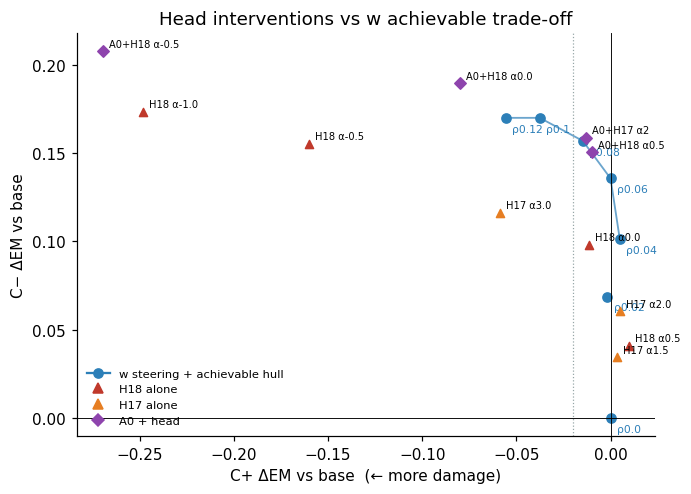

In [ ]:
# ===== Cell 26 — w 곡선 조밀화(ρ 0.02–0.10) + 오목 껍질(혼합 정책 달성 가능 곡선) 기준 재판정 =====
RHO_GRID = [0.02, 0.04, 0.08, 0.10]
WEM = {0.0: EMB, 0.06: EM0, 0.12: EM1}
for r in RHO_GRID:
    d = generate(f'w_r{r}_xfit_{W_TAG}', delta_xfit(r)); WEM[r] = em_row(d)
    print(f'   ρ{r}: hit_limit {d.hit_limit.mean():.3f}')
RHOS = sorted(WEM)

# (26-1) w 곡선
rows26 = [dict(rho=r, C_minus=boot(WEM[r] - EMB, C == 0), C_plus=boot(WEM[r] - EMB, C == 1)) for r in RHOS]
print(pd.DataFrame(rows26).to_string(index=False))

# (26-2) 오목 상한 껍질: x=C+ ΔEM, y=C− ΔEM
def upper_hull(px, py):
    o = np.lexsort((py, px)); P = list(zip(px[o], py[o])); H = []
    for p in P:
        while len(H) >= 2 and (H[-1][0]-H[-2][0])*(p[1]-H[-2][1]) - (H[-1][1]-H[-2][1])*(p[0]-H[-2][0]) >= 0: H.pop()
        H.append(p)
    hx, hy = map(np.array, zip(*H)); return hx, hy
WX = np.stack([xy(WEM[r], S)[0] for r in RHOS]); WY = np.stack([xy(WEM[r], S)[1] for r in RHOS])     # (7, B)
wx0 = np.array([(WEM[r][IP] - EMB[IP]).mean() for r in RHOS]); wy0 = np.array([(WEM[r][IM] - EMB[IM]).mean() for r in RHOS])
hx0, hy0 = upper_hull(wx0, wy0)
print('(26-2) 점추정 껍질 꼭짓점 (C+Δ, C−Δ):', [(round(a, 4), round(b, 4)) for a, b in zip(hx0, hy0)])

rows27 = []
for nm, e in CONDS.items():
    x0, y0 = (e[IP] - EMB[IP]).mean(), (e[IM] - EMB[IM]).mean()
    inr = hx0.min() <= x0 <= hx0.max()
    xb, yb = xy(e, S); dv = np.full(B, np.nan)
    for b in range(B):
        hx, hy = upper_hull(WX[:, b], WY[:, b])
        if hx.min() <= xb[b] <= hx.max(): dv[b] = yb[b] - np.interp(xb[b], hx, hy)
    ok = ~np.isnan(dv); lo, hi = (np.quantile(dv[ok], [.025, .975]) if ok.mean() > .9 else (np.nan, np.nan))
    v0 = y0 - np.interp(x0, hx0, hy0) if inr else np.nan
    verdict = ('범위 밖' if not inr or ok.mean() <= .9 else 'w보다 우위' if lo > 0 else 'w보다 열위' if hi < 0 else
               f'동등(±{MARGIN})' if (lo > -MARGIN and hi < MARGIN) else '판정 불가')
    rows27.append(dict(cond=nm, x_Cp=round(x0, 4), y_Cm=round(y0, 4), in_range=inr, boot_in=round(ok.mean(), 2),
                       vert_diff=None if np.isnan(v0) else round(v0, 4), CI=[round(lo, 4), round(hi, 4)], verdict=verdict))
T26 = pd.DataFrame(rows27); print(T26.to_string(index=False)); T26.to_csv(ROOT/'e15_tradeoff_hull.csv', index=False)

# (26-3) 그림 F13: w 곡선 + 껍질 + head 조건
fig, ax = plt.subplots(figsize=(6.4, 4.6))
ax.plot(wx0, wy0, 'o', c=BLUE, label='w steering (ρ 0–0.12)')
for r, a, b in zip(RHOS, wx0, wy0): ax.annotate(f'ρ{r}', (a, b), textcoords='offset points', xytext=(4, -9), fontsize=7, color=BLUE)
ax.plot(hx0, hy0, '-', c=BLUE, lw=1.2, alpha=.7, label='w achievable (upper hull)')
for nm, e in CONDS.items():
    x0, y0 = (e[IP] - EMB[IP]).mean(), (e[IM] - EMB[IM]).mean()
    c = PRI if 'H18' in nm and 'A0' not in nm else ORG if 'H17' in nm and 'A0' not in nm else PUR
    ax.scatter(x0, y0, c=c, marker='D' if 'A0' in nm else '^', s=28, zorder=3)
    ax.annotate(nm, (x0, y0), textcoords='offset points', xytext=(4, 3), fontsize=6.5)
ax.axvline(-0.02, c=GRAY, ls=':', lw=.8); ax.axhline(0, c='k', lw=.6); ax.axvline(0, c='k', lw=.6)
ax.set_xlabel('C+ ΔEM vs base  (← more damage)'); ax.set_ylabel('C− ΔEM vs base')
ax.legend(handles=[plt.Line2D([], [], c=BLUE, marker='o', label='w steering + achievable hull'),
                   plt.Line2D([], [], c=PRI, marker='^', ls='', label='H18 alone'), plt.Line2D([], [], c=ORG, marker='^', ls='', label='H17 alone'),
                   plt.Line2D([], [], c=PUR, marker='D', ls='', label='A0 + head')], frameon=False, fontsize=7.5, loc='lower left')
ax.set_title('Head interventions vs w achievable trade-off'); save(fig, 'F13_tradeoff_hull')

# 결과 시각화

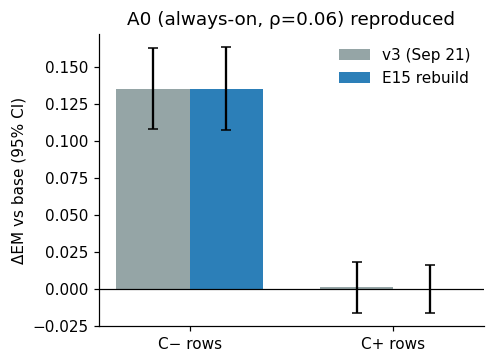

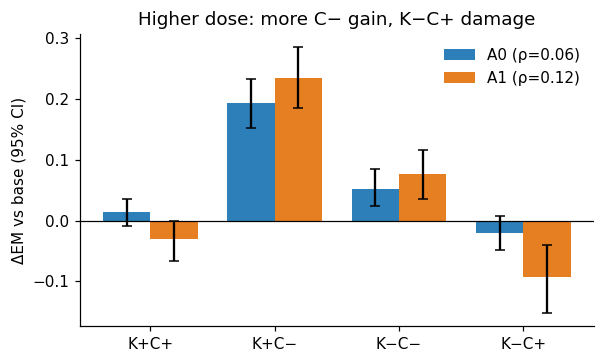

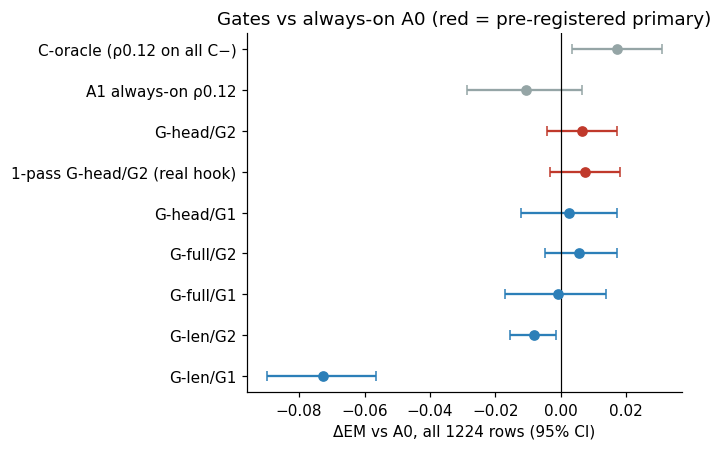

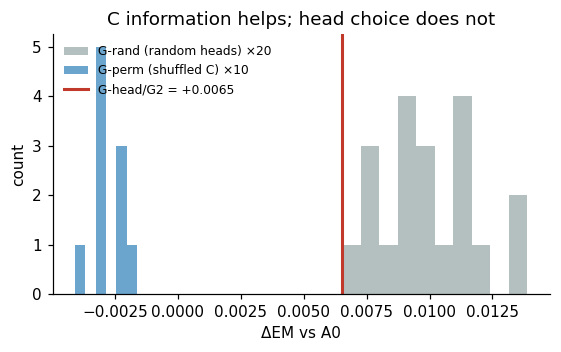

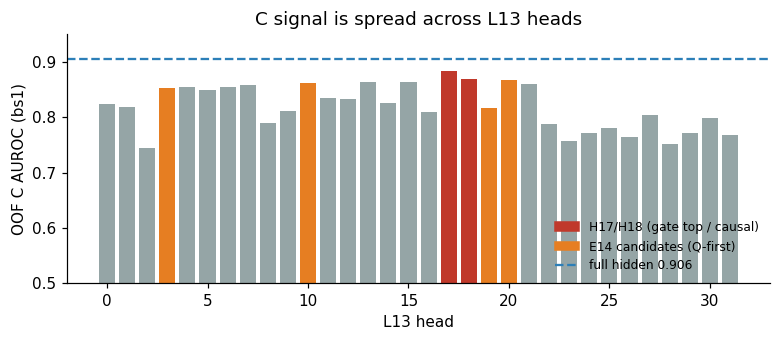

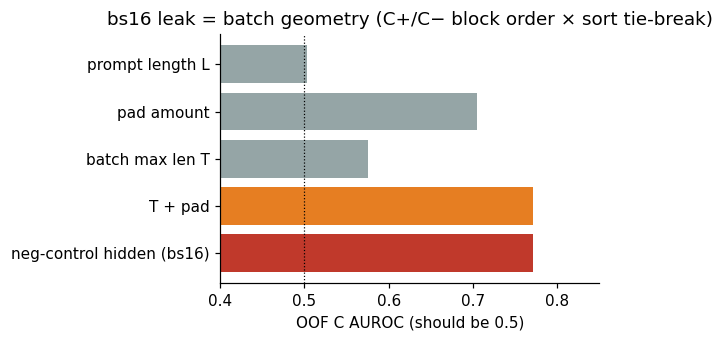

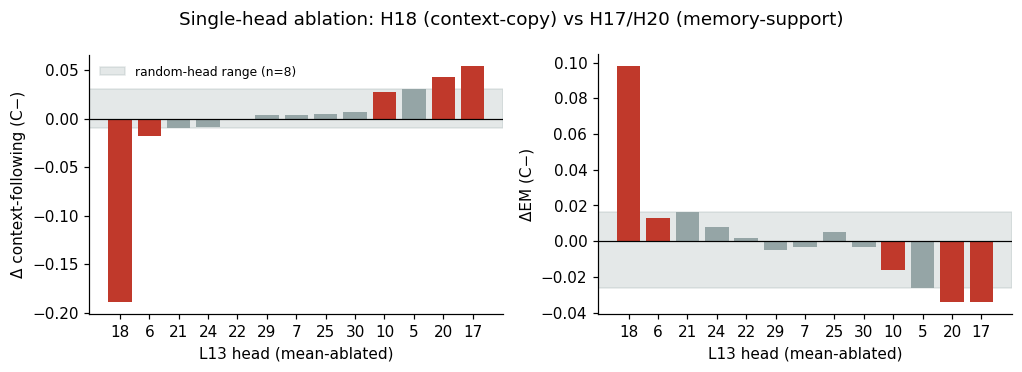

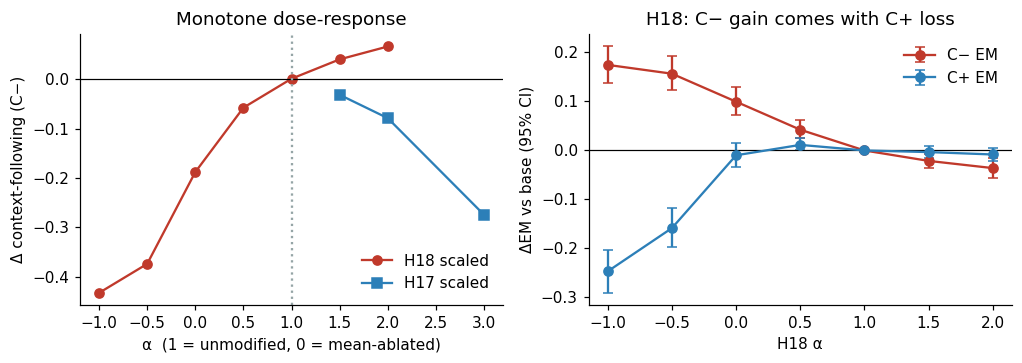

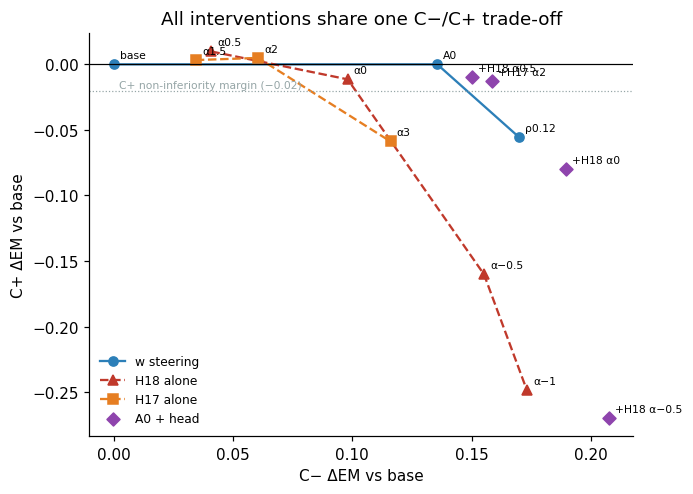

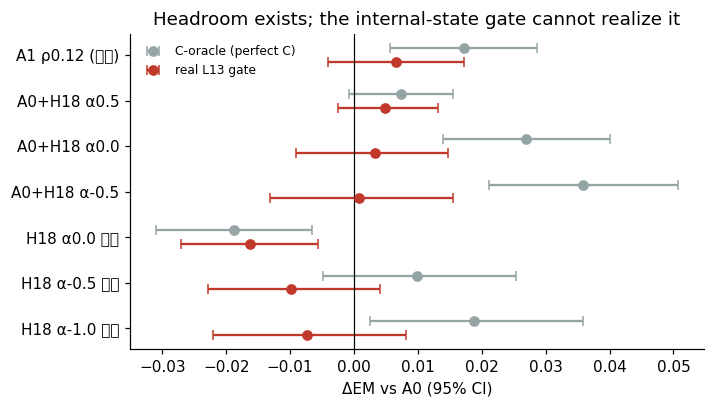

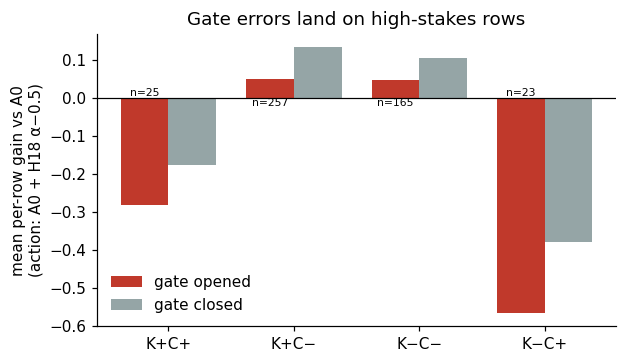

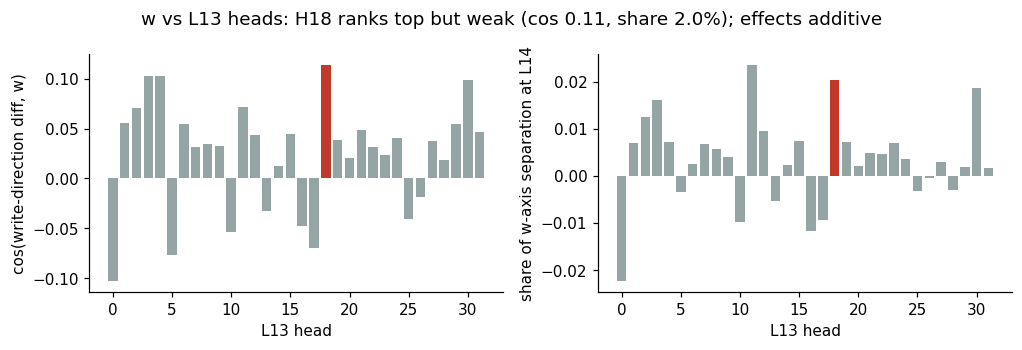

saved: ['F01_A0_reproduction.png', 'F02_dose_by_cell.png', 'F03_gate_forest.png', 'F04_null_specificity.png', 'F05_head_C_auroc.png', 'F06_negative_control.png', 'F07_head_ablation.png', 'F08_dose_response.png', 'F09_tradeoff_frontier.png', 'F10_headroom_vs_gate.png', 'F11_gate_error_correlation.png', 'F12_w_h18_link.png']


In [ ]:
# ===== Cell 21 — 보고용 그림 12장 (개별 PNG, 한 그림 최대 2 panel) =====
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
FIG = ROOT/'figs'; FIG.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
CELLS = ['K+C+', 'K+C−', 'K−C−', 'K−C+']
PRI, GRAY, BLUE, ORG, PUR = '#c0392b', '#95a5a6', '#2c7fb8', '#e67e22', '#8e44ad'
def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG/f'{name}.png', bbox_inches='tight'); plt.show(); plt.close(fig)
def mci(b): m, (lo, hi) = b; return m, m - lo, hi - m
def bars(ax, x, bs, width, **kw):
    m = np.array([b[0] for b in bs]); lo = np.array([b[1][0] for b in bs]); hi = np.array([b[1][1] for b in bs])
    ax.bar(x, m, width, yerr=[m - lo, hi - m], capsize=3, **kw)
pt = lambda e: ((e - EMB)[C == 0].mean(), (e - EMB)[C == 1].mean())

# (F01) A0 재현
fig, ax = plt.subplots(figsize=(4.6, 3.4)); x = np.arange(2)
bars(ax, x - .18, [(0.1356, [0.108, 0.163]), (0.0016, [-0.016, 0.018])], .36, color=GRAY, label='v3 (Sep 21)')
bars(ax, x + .18, [boot(EM0 - EMB, C == 0), boot(EM0 - EMB, C == 1)], .36, color=BLUE, label='E15 rebuild')
ax.axhline(0, c='k', lw=.8); ax.set_xticks(x, ['C− rows', 'C+ rows']); ax.set_ylabel('ΔEM vs base (95% CI)')
ax.set_title('A0 (always-on, ρ=0.06) reproduced'); ax.legend(frameon=False); save(fig, 'F01_A0_reproduction')

# (F02) 셀별 A0 vs ρ0.12
fig, ax = plt.subplots(figsize=(5.6, 3.4)); x = np.arange(4)
bars(ax, x - .19, [boot(EM0 - EMB, st == s) for s in range(4)], .38, color=BLUE, label='A0 (ρ=0.06)')
bars(ax, x + .19, [boot(EM1 - EMB, st == s) for s in range(4)], .38, color=ORG, label='A1 (ρ=0.12)')
ax.axhline(0, c='k', lw=.8); ax.set_xticks(x, CELLS); ax.set_ylabel('ΔEM vs base (95% CI)')
ax.set_title('Higher dose: more C− gain, K−C+ damage'); ax.legend(frameon=False); save(fig, 'F02_dose_by_cell')

# (F03) gate forest plot
arms = [('C-oracle (ρ0.12 on all C−)', boot(EMCO - EM0, ALL), GRAY), ('A1 always-on ρ0.12', boot(EM1 - EM0, ALL), GRAY)]
for r in RES: arms.append((r['arm'], r['vsA0_all'], PRI if r['arm'] == 'G-head/G2' else BLUE))
arms.insert(3, ('1-pass G-head/G2 (real hook)', boot(OP.em.to_numpy() - EM0, ALL), PRI))
fig, ax = plt.subplots(figsize=(6.4, 4.2)); y = np.arange(len(arms))[::-1]
for yi, (nm, b, c) in zip(y, arms):
    m, l, h = mci(b); ax.errorbar(m, yi, xerr=[[l], [h]], fmt='o', color=c, capsize=3)
ax.axvline(0, c='k', lw=.8); ax.set_yticks(y, [a[0] for a in arms]); ax.set_xlabel('ΔEM vs A0, all 1224 rows (95% CI)')
ax.set_title('Gates vs always-on A0 (red = pre-registered primary)'); save(fig, 'F03_gate_forest')

# (F04) 특이성 null
fig, ax = plt.subplots(figsize=(5.2, 3.3))
ax.hist(NR, bins=10, alpha=.7, color=GRAY, label='G-rand (random heads) ×20')
ax.hist(NP, bins=6, alpha=.7, color=BLUE, label='G-perm (shuffled C) ×10')
ax.axvline(obs, c=PRI, lw=2, label=f'G-head/G2 = {obs:+.4f}')
ax.set_xlabel('ΔEM vs A0'); ax.set_ylabel('count'); ax.set_title('C information helps; head choice does not')
ax.legend(frameon=False, fontsize=8); save(fig, 'F04_null_specificity')

# (F05) head별 C AUROC
fig, ax = plt.subplots(figsize=(7.2, 3.2))
cols = [PRI if h in (17, 18) else (ORG if h in (20, 10, 19, 3) else GRAY) for h in range(NH)]
ax.bar(range(NH), auc_head, color=cols); ax.axhline(auc_full, c=BLUE, ls='--')
ax.set_ylim(.5, .95); ax.set_xlabel('L13 head'); ax.set_ylabel('OOF C AUROC (bs1)'); ax.set_title('C signal is spread across L13 heads')
ax.legend(handles=[Patch(color=PRI, label='H17/H18 (gate top / causal)'), Patch(color=ORG, label='E14 candidates (Q-first)'),
                   plt.Line2D([], [], c=BLUE, ls='--', label=f'full hidden {auc_full:.3f}')], frameon=False, fontsize=8, loc='lower right')
save(fig, 'F05_head_C_auroc')

# (F06) 음성대조 진단
aucs = {}
for nm, cc in [('prompt length L', ['L']), ('pad amount', ['pad']), ('batch max len T', ['T']), ('T + pad', ['T', 'pad'])]:
    X = pd.get_dummies(M[cc].astype(str)).to_numpy(float); aucs[nm] = roc_auc_score(YC, oof_prob(X, YC, C_=1.0))
aucs['neg-control hidden (bs16)'] = auc_neg
fig, ax = plt.subplots(figsize=(5.8, 3.2)); ks = list(aucs)[::-1]
ax.barh(ks, [aucs[k] for k in ks], color=[PRI if 'hidden' in k else (ORG if 'T + pad' == k else GRAY) for k in ks])
ax.axvline(.5, c='k', lw=.8, ls=':'); ax.set_xlim(.4, .85); ax.set_xlabel('OOF C AUROC (should be 0.5)')
ax.set_title('bs16 leak = batch geometry (C+/C− block order × sort tie-break)'); save(fig, 'F06_negative_control')

# (F07) 단일 head ablation (2 panel)
R_ = T14[T14.group == 'rand']; od = T14.sort_values('dFC_Cm')
fig, axs = plt.subplots(1, 2, figsize=(9.4, 3.4))
for ax, col, lab in [(axs[0], 'dFC_Cm', 'Δ context-following (C−)'), (axs[1], 'dEM_Cm', 'ΔEM (C−)')]:
    ax.axhspan(R_[col].min(), R_[col].max(), color=GRAY, alpha=.25, label='random-head range (n=8)')
    ax.bar(od['head'].astype(str), od[col], color=[PRI if g == 'cand' else GRAY for g in od.group])
    ax.axhline(0, c='k', lw=.8); ax.set_ylabel(lab); ax.set_xlabel('L13 head (mean-ablated)')
axs[0].legend(frameon=False, fontsize=8)
fig.suptitle('Single-head ablation: H18 (context-copy) vs H17/H20 (memory-support)'); save(fig, 'F07_head_ablation')

# (F08) 용량-반응 (2 panel)
al = sorted(ALPHAS_SOLO); a17 = [1.5, 2.0, 3.0]
fig, axs = plt.subplots(1, 2, figsize=(9.4, 3.4))
axs[0].plot(al, [((fc_of(RUNS[('solo', 18, a)]) - FCB)[C == 0]).mean() for a in al], 'o-', c=PRI, label='H18 scaled')
axs[0].plot(a17, [((fc_of(RUNS[('solo', 17, a)]) - FCB)[C == 0]).mean() for a in a17], 's-', c=BLUE, label='H17 scaled')
axs[0].axhline(0, c='k', lw=.8); axs[0].axvline(1, c=GRAY, ls=':'); axs[0].set_xlabel('α  (1 = unmodified, 0 = mean-ablated)')
axs[0].set_ylabel('Δ context-following (C−)'); axs[0].legend(frameon=False); axs[0].set_title('Monotone dose-response')
for lab, mk, c in [('C− EM', C == 0, PRI), ('C+ EM', C == 1, BLUE)]:
    bs = [boot(em_row(RUNS[('solo', 18, a)]) - EMB, mk) for a in al]
    m = np.array([b[0] for b in bs]); lo = np.array([b[1][0] for b in bs]); hi = np.array([b[1][1] for b in bs])
    axs[1].errorbar(al, m, yerr=[m - lo, hi - m], fmt='o-', c=c, capsize=3, label=lab)
axs[1].axhline(0, c='k', lw=.8); axs[1].set_xlabel('H18 α'); axs[1].set_ylabel('ΔEM vs base (95% CI)')
axs[1].legend(frameon=False); axs[1].set_title('H18: C− gain comes with C+ loss'); save(fig, 'F08_dose_response')

# (F09) 트레이드오프 곡선 ★
groups = [('w steering', [(0, 0), pt(EM0), pt(EM1)], ['base', 'A0', 'ρ0.12'], BLUE, 'o-'),
          ('H18 alone', [pt(em_row(RUNS[('solo', 18, a)])) for a in [0.5, 0.0, -0.5, -1.0]], ['α0.5', 'α0', 'α−0.5', 'α−1'], PRI, '^--'),
          ('H17 alone', [pt(em_row(RUNS[('solo', 17, a)])) for a in a17], ['α1.5', 'α2', 'α3'], ORG, 's--'),
          ('A0 + head', [pt(em_row(RUNS[('A0+', 18, a)])) for a in [0.5, 0.0, -0.5]] + [pt(em_row(RUNS[('A0+', 17, 2.0)]))],
           ['+H18 α0.5', '+H18 α0', '+H18 α−0.5', '+H17 α2'], PUR, None)]
fig, ax = plt.subplots(figsize=(6.4, 4.6))
for nm, ps, labs, c, sty in groups:
    xs, ys = zip(*ps)
    if sty: ax.plot(xs, ys, sty, c=c, label=nm)
    else: ax.scatter(xs, ys, c=c, marker='D', label=nm, zorder=3)
    for (x_, y_), l in zip(ps, labs): ax.annotate(l, (x_, y_), textcoords='offset points', xytext=(4, 4), fontsize=7)
ax.axhline(0, c='k', lw=.8); ax.axhline(-0.02, c=GRAY, ls=':', lw=.8)
ax.text(0.002, -0.018, 'C+ non-inferiority margin (−0.02)', fontsize=7, color=GRAY)
ax.set_xlabel('C− ΔEM vs base'); ax.set_ylabel('C+ ΔEM vs base'); ax.legend(frameon=False, fontsize=8, loc='lower left')
ax.set_title('All interventions share one C−/C+ trade-off'); save(fig, 'F09_tradeoff_frontier')

# (F10) 상한 vs 실제 gate
fig, ax = plt.subplots(figsize=(6.6, 3.8)); y = np.arange(len(T19))[::-1]
for yi, r in zip(y, T19.itertuples()):
    for off, b, c, lab in [(.15, r.C_oracle_vsA0, GRAY, 'C-oracle (perfect C)'), (-.15, r.gate_vsA0, PRI, 'real L13 gate')]:
        m, l, h = mci(b); ax.errorbar(m, yi + off, xerr=[[l], [h]], fmt='o', c=c, capsize=3, label=lab if yi == y[0] else None)
ax.axvline(0, c='k', lw=.8); ax.set_yticks(y, T19.action); ax.set_xlabel('ΔEM vs A0 (95% CI)')
ax.legend(frameon=False, fontsize=8); ax.set_title('Headroom exists; the internal-state gate cannot realize it'); save(fig, 'F10_headroom_vs_gate')

# (F11) gate 오류 상관 ★
fig, ax = plt.subplots(figsize=(5.8, 3.4)); x = np.arange(4)
ax.bar(x - .19, [gainX[(st == s) & O1h].mean() for s in range(4)], .38, color=PRI, label='gate opened')
ax.bar(x + .19, [gainX[(st == s) & ~O1h].mean() for s in range(4)], .38, color=GRAY, label='gate closed')
for s in range(4):
    ax.text(s - .19, 0, f'n={int(((st == s) & O1h).sum())}', ha='center', va='bottom' if gainX[(st == s) & O1h].mean() < 0 else 'top', fontsize=7)
ax.axhline(0, c='k', lw=.8); ax.set_xticks(x, CELLS); ax.set_ylabel('mean per-row gain vs A0\n(action: A0 + H18 α−0.5)')
ax.legend(frameon=False); ax.set_title('Gate errors land on high-stakes rows'); save(fig, 'F11_gate_error_correlation')

# (F12) w ↔ H18 연결 (2 panel)
fig, axs = plt.subplots(1, 2, figsize=(9.4, 3.2)); cc = [PRI if h == 18 else GRAY for h in range(NH)]
axs[0].bar(range(NH), T18.cos_w, color=cc); axs[0].set_xlabel('L13 head'); axs[0].set_ylabel('cos(write-direction diff, w)')
axs[1].bar(range(NH), T18.share_L14, color=cc); axs[1].set_xlabel('L13 head'); axs[1].set_ylabel('share of w-axis separation at L14')
fig.suptitle(f'w vs L13 heads: H18 ranks top but weak (cos {T18.cos_w[18]:.2f}, share {T18.share_L14[18]:.1%}); effects additive')
save(fig, 'F12_w_h18_link')
print('saved:', sorted(p.name for p in FIG.glob('*.png')))